# No Time to Train con ECGs: xECG congelado

El artículo *No Time to Train!* (arXiv:2507.02798) nombra objetos en imágenes sin entrenar nada: un encoder ya preentrenado
(DINOv2) se usa congelado, y cada objeto nuevo toma la clase del prototipo más parecido de un banco armado con pocas referencias
con etiqueta. Aquí se hace lo mismo con ECGs:
- **Encoder congelado:** xECG, que sus autores preentrenaron con SimDINOv2 en ECGs (sección 2). Sus pesos no cambian.
- **Banco de memoria:** los embeddings de 2,000 ECGs con etiqueta (sección 4).
- **Sin entrenar:** cada ECG nuevo se clasifica con sus vecinos del banco (k-NN) o con el promedio de cada etiqueta (prototipo) (sección 5).

Las secciones 6, 7 y 10 comparan con clasificadores que sí se entrenan sobre los mismos embeddings.

## 1. Lectura del dataset

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd

DATASET = Path("../data/processed/balanceado_jovenes_v3")

ecgs = pd.read_csv(DATASET / "ecgs.csv", index_col="fila")
particion = pd.read_csv(DATASET / "particion.csv", index_col="fila")
senales = np.load(DATASET / "senales.npy", mmap_mode="r")

print("Tabla de ECGs:", ecgs.shape)
print("Partición:", particion.shape)
print("Señales:", senales.shape, senales.dtype)
ecgs.head()

Tabla de ECGs: (20000, 9)
Partición: (20000, 25)
Señales: (20000, 5000, 12) float16


,registro,dataset,ruta,paciente,edad,sexo,grupo_edad,clase,cardiopatias
fila,,,,,,,,,
0,A5667,CPSC 2018,../data/raw/challenge-2020/1.0.2/training/cpsc...,NaN,12.0,F,<18,normal,NaN
1,JS40229,Ningbo,../data/raw/challenge-2021/1.0.3/training/ning...,NaN,6.0,M,<18,normal,NaN
2,A3713,CPSC 2018,../data/raw/challenge-2020/1.0.2/training/cpsc...,NaN,10.0,F,<18,normal,NaN
3,JS36800,Ningbo,../data/raw/challenge-2021/1.0.3/training/ning...,NaN,16.0,M,<18,normal,NaN
4,JS36474,Ningbo,../data/raw/challenge-2021/1.0.3/training/ning...,NaN,16.0,F,<18,normal,NaN


### 1.1 Entrenamiento, validación y prueba

Decisiones tomadas:
- La partición original del dataset v3: todos los ECGs de un paciente quedan del mismo lado.
- Con etiqueta: 2,000 ECGs de entrenamiento (1,000 con cardiopatía y 1,000 normales), como en la cohorte futura.
- Prueba final: el test del v3 y SPH (sección 9).

In [2]:
particion = particion[["dataset", "registro", "grupo", "y", "split", "etiquetado_2000_0"]].rename(columns={"etiquetado_2000_0": "etiquetado"})
etiquetados = particion.index[particion["etiquetado"]].to_numpy()     # 2,000 ECGs de entrenamiento con etiqueta
assert particion.groupby("grupo")["split"].nunique().max() == 1      # ningún paciente queda en dos lados

resumen = particion.groupby("split").agg(ECGs=("y", "size"), con_cardiopatia=("y", "sum"), pacientes=("grupo", "nunique"),
                                         con_etiqueta=("etiquetado", "sum"))
resumen["% del dataset"] = 100 * resumen["ECGs"] / resumen["ECGs"].sum()
resumen.loc[["train", "val", "test"]].rename(columns={"con_cardiopatia": "con cardiopatía", "con_etiqueta": "con etiqueta"}).round(1)

,ECGs,con cardiopatía,pacientes,con etiqueta,% del dataset
split,,,,,
train,13999,7002,13556,2000,70.0
val,2000,998,1936,0,10.0
test,4001,2000,3872,0,20.0


### 1.2 Cardiopatías en el dataset

ECGs por clase: {'normal': 10000, 'con cardiopatía': 10000}
Cardiopatías distintas: 43 | casos en total: 15817


,train,train con etiqueta,val,test,total
cardiopatía,,,,,
onda T anormal,1201,175,152,356,1709
cambios del segmento ST,931,138,132,244,1307
anomalía inespecífica ST-T,623,89,98,183,904
bloqueo de rama derecha,531,77,85,149,765
hipertrofia ventricular izquierda,525,71,79,144,748
QRS anormal,466,65,68,149,683
extrasístole ventricular,420,62,57,121,598
flutter auricular,408,50,56,127,591
onda T invertida,398,56,52,140,590


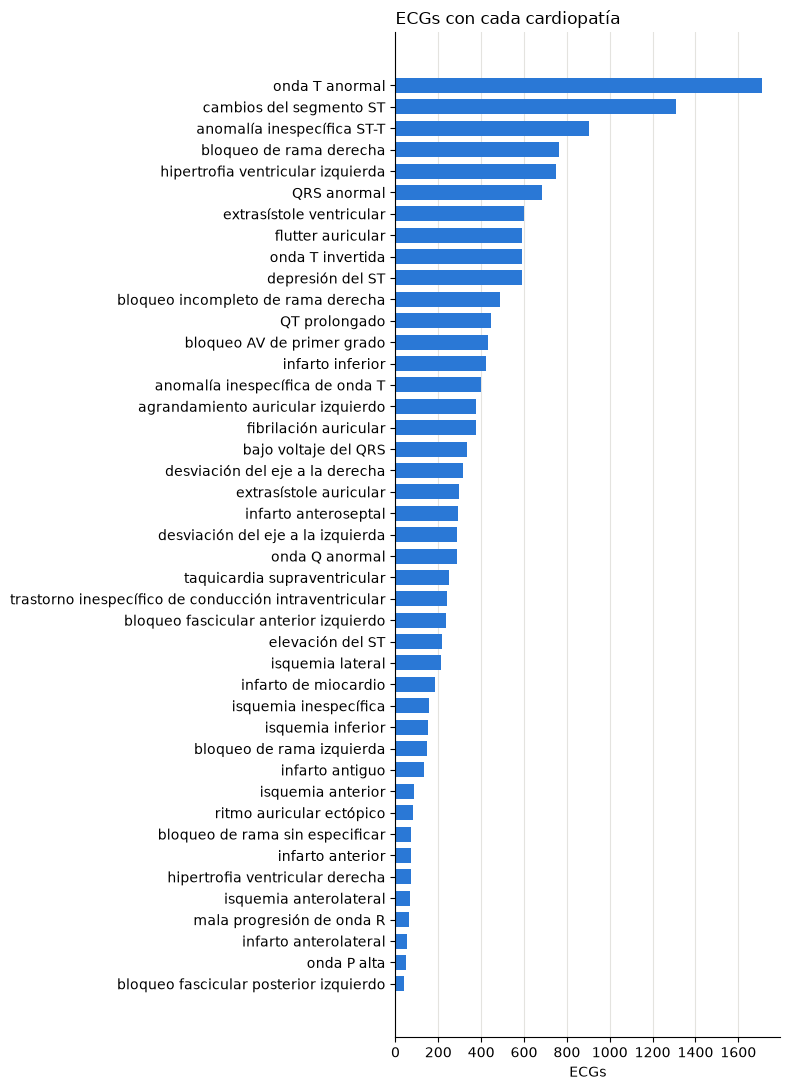

In [3]:
import matplotlib.pyplot as plt

cardiopatias = ecgs["cardiopatias"].str.split("; ").explode().dropna()   # un ECG puede tener varias
print("ECGs por clase:", ecgs["clase"].value_counts().to_dict())
print("Cardiopatías distintas:", cardiopatias.nunique(), "| casos en total:", len(cardiopatias))

conteo = pd.crosstab(cardiopatias.to_numpy(), particion.loc[cardiopatias.index, "split"].to_numpy())[["train", "val", "test"]]
conteo["total"] = conteo.sum(axis=1)
conteo["train con etiqueta"] = cardiopatias[particion.loc[cardiopatias.index, "etiquetado"].to_numpy()].value_counts()
conteo = conteo.fillna(0).astype(int)[["train", "train con etiqueta", "val", "test", "total"]]
conteo = conteo.sort_values("total", ascending=False).rename_axis(index="cardiopatía", columns=None)
display(conteo)

fig, ax = plt.subplots(figsize=(8, 11))
ax.barh(conteo.index[::-1], conteo["total"][::-1], color="#2a78d6", height=0.7)
ax.set_xlabel("ECGs")
ax.set_title("ECGs con cada cardiopatía", loc="left")
ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for borde in ["top", "right"]:
    ax.spines[borde].set_visible(False)
plt.tight_layout()
plt.show()

### 1.3 Las 111 características

Recordando lo que hicimos en el avance 2: Cada ECG se filtró de 0.5 a 40 Hz y en su latido mediano se midieron  características: amplitudes y áreas del QRS, ST y onda T por derivación, intervalos (PR, QRS, QT), onda P, ritmo, espectro, estadísticos de la señal y calidad.

,variables,nombres
familia,,
QRS: amplitud y eje,47,"q_patho_class, s_depth_II, q_depth_V1, cornell_product_mvms, sokolow_lyon_mv, s_depth_aVF, qrs_axis_sin, qrs_area_II, s_depth_III, q_depth_V2, r_amp_II, s_depth_V6, r_amp_aVR, s_depth_aVR, r_amp_V6, qrs_area_V6, qrs_area_III, s_depth_V5, qrs_area_V4, r_amp_V3, r_prog_slope_mv, s_depth_V1, q_depth_V3, s_depth_V4, qrs_area_aVR, qrs_axis_cos, r_amp_V2, qrs_area_I, s_depth_V3, qrs_area_V3, q_depth_V6, s_depth_I, qrs_area_V1, q_depth_aVF, q_depth_III, r_amp_III, r_frac_V1, s_depth_V2, q_depth_II, qrs_area_V2, q_depth_aVL, s_depth_aVL, axis_class_izquierda, axis_class_derecha, axis_class_extrema, r_transition_class_temprana, r_transition_class_tardia"
Repolarización (ST-T),27,"t_amp_aVR, st_min_mv, t_amp_V5, qrs_t_angle_deg, st_aVR, st_dep_lateral_mv, st_V5, t_amp_V4, t_axis_cos, t_peak_rms_mv, st_V4, t_amp_aVF, st_dep_inferior_mv, t_amp_aVL, st_aVL, t_amp_V3, st_dep_anterior_mv, st_elev_inferior_mv, t_axis_sin, t_amp_V1, st_V3, st_III, st_V1, t_amp_V2, st_max_mv, st_V2, t_inverted_any"
Estadísticos de la señal,23,"std_aVL, std_V5, std_III, std_V6, kurt_aVR, kurt_V6, kurt_V1, std_V1, std_I, std_aVR, kurt_V3, std_V4, kurt_II, std_aVF, kurt_I, std_V3, kurt_V4, std_V2, std_II, kurt_V2, kurt_aVL, kurt_III, kurt_aVF"
Intervalos,6,"qrs_class, qrs_dur_ms, pq_peak_ms, qtc_bazett_ms, qtc_class, pr_ms"
Espectro,3,"sp_entropy, sp_mid_rel, sp_low_rel"
Ritmo,3,"hr_bpm, beat_similarity, hr_class"
Calidad,1,noise_hf_frac
Onda P,1,flag_no_p_wave


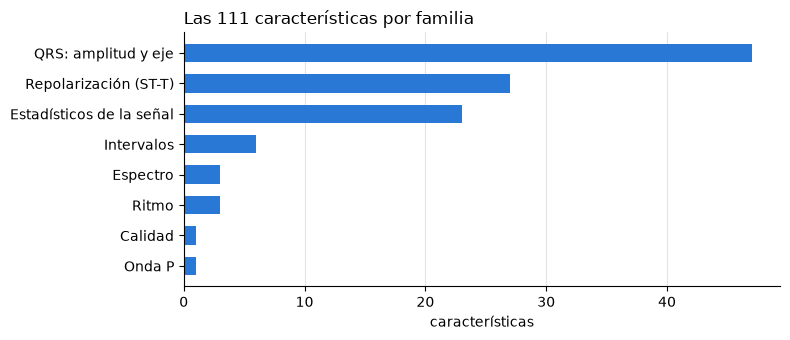

Tabla de las 111 características: (20000, 111)


,t_amp_aVR,qrs_class,q_patho_class,st_min_mv,t_amp_V5,qrs_t_angle_deg,qrs_dur_ms,st_aVR,st_dep_lateral_mv,st_V5,...,kurt_aVF,s_depth_aVL,st_V2,axis_class_izquierda,axis_class_derecha,axis_class_extrema,r_transition_class_temprana,r_transition_class_tardia,t_inverted_any,flag_no_p_wave
fila,,,,,,,,,,,,,,,,,,,,,
0,-0.747329,-0.233371,-0.417871,-1.044159,0.841577,0.539667,-0.158861,-0.991478,2.796256,0.957861,...,-1.359605,-1.929905,0.110793,-0.232342,-0.253135,-0.110874,-0.491749,-0.37116,-0.318051,-0.430291
1,-0.762159,-0.233371,-0.417871,0.997041,0.370010,0.156159,-1.852805,-0.360524,0.566479,0.028836,...,1.261163,1.167677,-0.294617,-0.232342,-0.253135,-0.110874,-0.491749,-0.37116,-0.318051,-0.430291
2,-0.735858,-0.233371,1.325210,0.774307,0.514805,0.494987,-0.626449,-0.460101,0.629720,0.558554,...,1.038484,-0.069046,0.682571,-0.232342,-0.253135,-0.110874,2.033559,-0.37116,-0.318051,2.324006
3,-2.641114,-0.233371,-0.417871,2.901073,2.964724,-0.454852,0.572647,-2.482150,0.976037,1.973083,...,-0.200239,1.075786,1.334754,-0.232342,-0.253135,-0.110874,2.033559,-0.37116,-0.318051,-0.430291
4,-0.906234,-0.233371,-0.417871,0.155095,0.068942,-0.266094,-0.892583,-1.062677,-0.343649,0.508987,...,1.738529,-0.082548,0.487514,-0.232342,-0.253135,-0.110874,-0.491749,-0.37116,-0.318051,-0.430291


In [4]:
import sys
import warnings

sys.path.insert(0, "..")
from ecg_experiment import caracteristicas_avance2 as ca2   # el código de extracción del Avance 2

warnings.simplefilter("ignore", pd.errors.PerformanceWarning)

variables = pd.read_csv("../outputs/avance2_fusion/variables_finales.csv")   # las 111 que eligió el Avance 2
familias = variables.groupby("familia")["variable"].agg(["size", ", ".join]).set_axis(["variables", "nombres"], axis=1)
familias = familias.sort_values("variables", ascending=False)
with pd.option_context("display.max_colwidth", None):
    display(familias)

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.barh(familias.index[::-1], familias["variables"][::-1], color="#2a78d6", height=0.6)
ax.set_xlabel("características")
ax.set_title("Las 111 características por familia", loc="left")
ax.grid(axis="x", color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
for borde in ["top", "right"]:
    ax.spines[borde].set_visible(False)
plt.tight_layout()
plt.show()

# Se miden en los primeros 9.6 s (4,800 muestras) de cada ECG
primarias = pd.DataFrame([ca2.extract(np.asarray(senales[i, :4800], dtype=np.float32)) for i in ecgs.index], index=ecgs.index)
primarias["implausible"] = primarias["implausible"].fillna("")
derivadas = ca2.derive(primarias)

# Imputación, recorte, codificación y estandarización ajustados solo con el entrenamiento, como en el Avance 2
train = particion.index[particion["split"] == "train"]
preprocesador = ca2.Preprocessor(variables["variable"].tolist()).fit(derivadas.loc[train])
caracteristicas = preprocesador.transform(derivadas)
print("Tabla de las 111 características:", caracteristicas.shape)
caracteristicas.head()

## 2. Encoder xLSTM con los pesos de xECG

En esta sección no se entrena nada: se arma el encoder, la red que convierte cada ECG en un vector de 1,024 números (su
embedding), y se le cargan los pesos que publicaron los autores de xECG (Lunelli et al., *npj Digital Medicine*, 2026).

- **xECG**: un modelo base (*foundation model*) para ECG. Es un encoder xLSTM que sus autores preentrenaron sin etiquetas, con
  SimDINOv2: dos copias del encoder, alumno y maestro, ven recortes distintos del mismo ECG, y el alumno aprende a describirlos
  igual que el maestro. Ese preentrenamiento no se repite aquí: se usan los pesos que resultaron.
- **xLSTM**: una red recurrente, de la familia de las LSTM, no un Transformer. Lee los tokens uno tras otro y guarda una memoria
  de lo que lleva leído, en vez de comparar todos los tokens entre sí con atención.
- **Pesos**: los números que la red aprendió en ese preentrenamiento. Sin ellos, el encoder empezaría con números al azar.

### 2.1 Variables

Cuánto dura cada token y el tamaño de la red.

- **Números en un token** = `DERIVACIONES` × `SEGUNDOS_TOKEN` × `FS` = 12 × 0.25 × 100 = 12 × 25 = 300
- **Tokens en una ventana** = segundos de la ventana ÷ `SEGUNDOS_TOKEN`:
  - ECG completo: 10 ÷ 0.25 = 40
  - token: 0.25 ÷ 0.25 = 1

In [5]:
import torch
import torch.nn.functional as F
from scipy.signal import resample_poly
from torch import nn

FS = 100                     # Hz: las señales del v3 vienen a 500 Hz y se bajan a 100, como las usa xECG
SEGUNDOS_ECG = 10.0          # el ECG completo
SEGUNDOS_TOKEN = 0.25        # un token es un trozo de 0.25 s de las 12 derivaciones
DERIVACIONES = 12            # en el orden que pide xECG: I, II, III, aVR, aVL, aVF, V1 a V6 (el mismo del v3)
ANCHO = 1024                 # números con los que se describe cada token
CABEZAS = 4                  # cabezas de cada bloque
BLOQUES = "ssmmssmms"        # 9 bloques, uno encima de otro: s = sLSTM, m = mLSTM
# FS, SEGUNDOS_TOKEN, ANCHO, CABEZAS y BLOQUES son los de xECG (su config.json, sección 2.3): sus pesos solo encajan en una red así
PESOS_XECG = Path("../outputs/notebook19_xecg_congelado/pesos_xecg/model.safetensors")     # se bajan en la sección 2.3

muestras_token = round(SEGUNDOS_TOKEN * FS)
tokens_ecg = round(SEGUNDOS_ECG / SEGUNDOS_TOKEN)

ventanas = pd.DataFrame({"segundos": [SEGUNDOS_ECG, SEGUNDOS_TOKEN], "por ECG": [1, tokens_ecg]}, index=["ECG completo", "token"])
ventanas[f"muestras a {FS} Hz"] = (ventanas["segundos"] * FS).round().astype(int)
ventanas["tokens"] = (ventanas[f"muestras a {FS} Hz"] // muestras_token).astype(int)
display(ventanas)

,segundos,por ECG,muestras a 100 Hz,tokens
ECG completo,10.00,1,1000,40
token,0.25,40,25,1


### 2.2 Tokens de un ECG

La derivación II de un ECG normal de entrenamiento partida en tokens de 0.25 s.

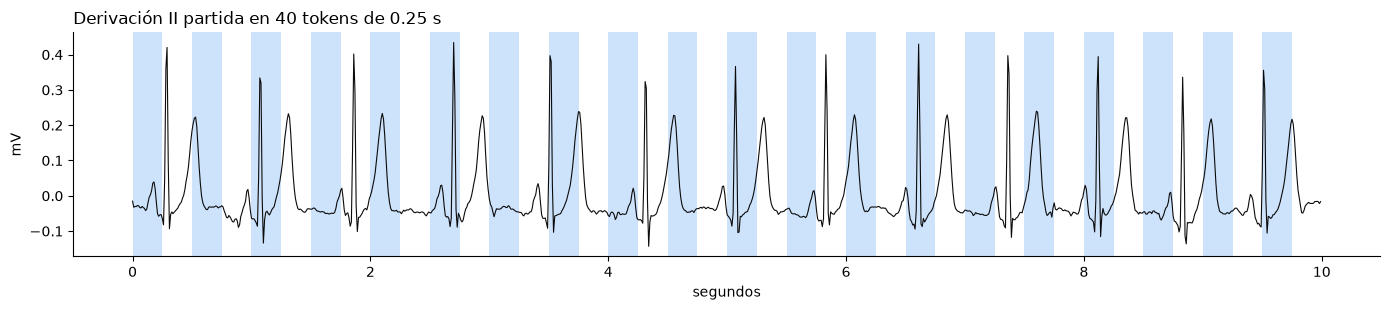

In [6]:
fila = ecgs.index[(particion["split"] == "train") & (ecgs["clase"] == "normal")][0]
ecg = resample_poly(np.asarray(senales[fila], dtype=np.float32), FS, 500, axis=0)   # de 500 Hz a FS: (1000, 12)
tiempo = np.arange(len(ecg)) / FS

fig, ax = plt.subplots(figsize=(14, 3.2))
for i in range(0, tokens_ecg, 2):
    ax.axvspan(i * SEGUNDOS_TOKEN, (i + 1) * SEGUNDOS_TOKEN, color="#cde2fb", linewidth=0)
ax.plot(tiempo, ecg[:, 1], color="#0b0b0b", linewidth=0.8)
ax.set_title(f"Derivación II partida en {tokens_ecg} tokens de {SEGUNDOS_TOKEN} s", loc="left")
ax.set(xlabel="segundos", ylabel="mV")
for borde in ["top", "right"]:
    ax.spines[borde].set_visible(False)
plt.tight_layout()
plt.show()

### 2.3 Los pesos de xECG

Los autores de xECG publicaron sus pesos en Hugging Face, en el repositorio `riccardolunelli/xECG_base_model_v1`, con licencia
MIT: se pueden usar y modificar siempre que se conserve el aviso de la licencia. Según su artículo, los preentrenaron con
SimDINOv2, sin etiquetas, en CODE, Chapman/Ningbo e INCART (Chapman y Ningbo también están en el v3).

Se bajan cuatro archivos de una versión fija del repositorio (su revisión):
- `model.safetensors`: los pesos.
- `config.json`: el tamaño de la red.
- `xECG.py`: el código con el que sus autores arman la red.
- `README.md`: la ficha del modelo, con la licencia.

In [7]:
import hashlib
import json
import urllib.request

REPOSITORIO = "riccardolunelli/xECG_base_model_v1"           # https://huggingface.co/riccardolunelli/xECG_base_model_v1
REVISION = "b06053253a9bd21445d8189b21813484929a3ffa"         # versión fija del repositorio: siempre se bajan los mismos archivos
ARCHIVOS = ["model.safetensors", "config.json", "xECG.py", "README.md"]

# Descarga: cada archivo tiene una dirección pública en Hugging Face (unos 228 MB en total)
PESOS_XECG.parent.mkdir(parents=True, exist_ok=True)
for nombre in ARCHIVOS:
    urllib.request.urlretrieve(f"https://huggingface.co/{REPOSITORIO}/resolve/{REVISION}/{nombre}", PESOS_XECG.parent / nombre)

# Comprobación: Hugging Face publica el tamaño de cada archivo y la huella SHA-256 de los grandes; los bajados tienen que coincidir
publicados = {e["path"]: e for e in json.load(urllib.request.urlopen(f"https://huggingface.co/api/models/{REPOSITORIO}/tree/{REVISION}"))}
comprobacion = pd.DataFrame([{"archivo": nombre,
                              "bytes publicados": publicados[nombre]["size"],
                              "bytes bajados": (PESOS_XECG.parent / nombre).stat().st_size,
                              "SHA-256 publicado": publicados[nombre].get("lfs", {}).get("oid", "(no la publica)"),
                              "SHA-256 bajado": hashlib.sha256((PESOS_XECG.parent / nombre).read_bytes()).hexdigest()}
                             for nombre in ARCHIVOS]).set_index("archivo")
assert (comprobacion["bytes publicados"] == comprobacion["bytes bajados"]).all()
assert comprobacion.loc["model.safetensors", "SHA-256 publicado"] == comprobacion.loc["model.safetensors", "SHA-256 bajado"]

print("Licencia en README.md:", next(linea for linea in (PESOS_XECG.parent / "README.md").read_text().splitlines() if linea.startswith("license")))
with pd.option_context("display.max_colwidth", None):
    display(comprobacion)

Licencia en README.md: license: mit


,bytes publicados,bytes bajados,SHA-256 publicado,SHA-256 bajado
archivo,,,,
model.safetensors,228099912,228099912,812dec69ac0fbf13f39e50bde4f35f85435a66966d8785baec65c2b5c70e722c,812dec69ac0fbf13f39e50bde4f35f85435a66966d8785baec65c2b5c70e722c
config.json,355,355,(no la publica),23ba68fc4edc5883f4a89a55f8da3d866ab040e64a46c9c862fde4bb52459b4a
xECG.py,7678,7678,(no la publica),373fed5a125abea218c74a8dc5b09e6054e85172a91f99e2ed47f8221fbe266f
README.md,1451,1451,(no la publica),5ed1dde84231713e5d8d28dd6f532b552df3df33123d72a41027b80d7d86e920


In [8]:
# Cómo es model.safetensors por dentro: 8 bytes con el largo de la cabecera; la cabecera, un texto JSON con el nombre, el tipo,
# la forma y el lugar de cada tensor; y después todos los números seguidos, en float32 (4 bytes cada uno)
with open(PESOS_XECG, "rb") as archivo:
    largo_cabecera = int.from_bytes(archivo.read(8), "little")
    cabecera = json.loads(archivo.read(largo_cabecera))
cabecera.pop("__metadata__", None)
print(f"{PESOS_XECG.stat().st_size:,} bytes = 8 + {largo_cabecera:,} de cabecera + {PESOS_XECG.stat().st_size - 8 - largo_cabecera:,} de números")
print("Las 2 primeras entradas de la cabecera:")
print(json.dumps(dict(list(cabecera.items())[:2]), indent=1))

# Cuántos números hay en cada parte de la red
tensores = pd.DataFrame([{"tensor": nombre, "forma": tuple(datos["shape"]), "números": int(np.prod(datos["shape"]))}
                         for nombre, datos in cabecera.items()])
bloque = tensores["tensor"].str.extract(r"blocks\.(\d+)\.")[0]
tensores["parte"] = bloque.map(lambda b: f"bloque {b} ({BLOQUES[int(b)]}LSTM)", na_action="ignore").fillna(tensores["tensor"])
partes = tensores.groupby("parte", sort=False).agg(tensores=("tensor", "size"), números=("números", "sum"))
partes.loc["total"] = partes.sum()
display(partes)

# El tamaño de la red según config.json, junto a las variables de la sección 2.1
config = json.loads((PESOS_XECG.parent / "config.json").read_text())
pd.DataFrame({"config.json": [config["sampling_freq"], config["patch_size"], config["embedding_size"], config["num_heads"], "".join(config["xlstm_config"])],
              "este notebook": [FS, muestras_token, ANCHO, CABEZAS, BLOQUES]},
             index=["FS (Hz)", "muestras por token", "ANCHO", "CABEZAS", "BLOQUES"])

228,099,912 bytes = 8 + 14,016 de cabecera + 228,085,888 de números
Las 2 primeras entradas de la cabecera:
{
 "core.model.blocks.0.ffn.proj_down.weight": {
  "dtype": "F32",
  "shape": [
   1024,
   1344
  ],
  "data_offsets": [
   0,
   5505024
  ]
 },
 "core.model.blocks.0.ffn.proj_up.weight": {
  "dtype": "F32",
  "shape": [
   2688,
   1024
  ],
  "data_offsets": [
   5505024,
   16515072
  ]
 }
}


,tensores,números
parte,,
bloque 0 (sLSTM),13,6238208
bloque 1 (sLSTM),13,6238208
bloque 2 (mLSTM),14,6380552
bloque 3 (mLSTM),14,6380552
bloque 4 (sLSTM),13,6238208
bloque 5 (sLSTM),13,6238208
bloque 6 (mLSTM),14,6380552
bloque 7 (mLSTM),14,6380552
bloque 8 (sLSTM),13,6238208


,config.json,este notebook
FS (Hz),100,100
muestras por token,25,25
ANCHO,1024,1024
CABEZAS,4,4
BLOQUES,ssmmssmms,ssmmssmms


Los primeros 8 números del patrón 0 en la derivación II: [-0.0176 -0.0154 -0.0251 -0.0078 -0.0377  0.0207 -0.0271  0.0203]


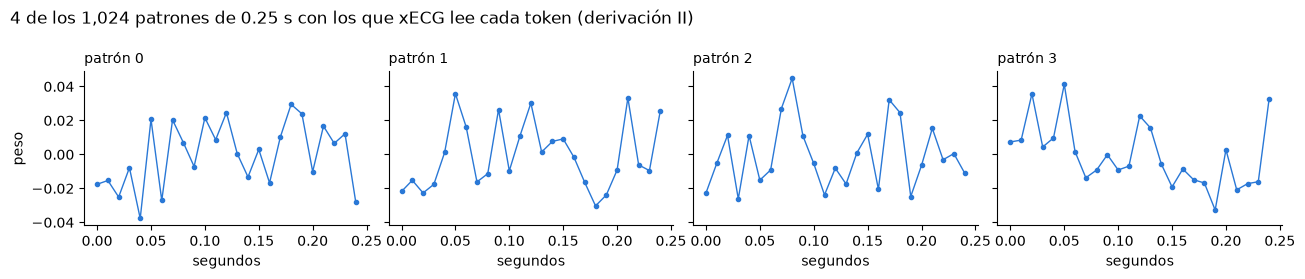

In [9]:
# Así se ven unos pesos: el primer paso de la red compara cada token (12 derivaciones × 25 muestras) con 1,024 patrones del mismo
# tamaño (tensor patch_embedding.conv.weight). Cada uno de los 1,024 números del token es el producto punto con uno de ellos.
from safetensors.torch import load_file

patrones = load_file(PESOS_XECG)["patch_embedding.conv.weight"]        # (1024 patrones, 12 derivaciones, 25 muestras)
print("Los primeros 8 números del patrón 0 en la derivación II:", np.round(patrones[0, 1, :8].numpy(), 4))

fig, ejes = plt.subplots(1, 4, figsize=(13, 2.8), sharey=True)
for numero, ax in enumerate(ejes):
    ax.plot(np.arange(muestras_token) / FS, patrones[numero, 1].numpy(), color="#2a78d6", marker="o", markersize=3, linewidth=1)
    ax.set_title(f"patrón {numero}", loc="left", fontsize=10)
    ax.set_xlabel("segundos")
    for borde in ["top", "right"]:
        ax.spines[borde].set_visible(False)
ejes[0].set_ylabel("peso")
fig.suptitle(f"4 de los {ANCHO:,} patrones de {SEGUNDOS_TOKEN} s con los que xECG lee cada token (derivación II)", x=0.01, ha="left")
plt.tight_layout()
plt.show()

### 2.4 Encoder xLSTM

El encoder de xECG es una pila de 9 bloques xLSTM, una red recurrente: cada bloque lee los tokens en orden, uno tras otro, y guarda una memoria
de lo que lleva leído. Cada bloque lee los tokens en sentido contrario al anterior. Hay dos tipos de bloque:
- **sLSTM**: su memoria es un número por dimensión, que se actualiza token por token.
- **mLSTM**: su memoria es una matriz por cabeza que guarda pares clave-valor; se calcula para todos los tokens a la vez.

Las piezas se escriben con los nombres que tienen en la librería `xlstm` (versión 2.0.4) para que los pesos de xECG entren tal cual.

In [10]:
class Norma(nn.Module):
    """LayerNorm de xLSTM: el peso guardado es lo que se le suma a 1, y no hay sesgo."""
    def __init__(self, ancho: int) -> None:
        super().__init__()
        self.weight = nn.Parameter(torch.zeros(ancho))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return F.layer_norm(x, (x.shape[-1],), 1 + self.weight, eps=1e-5)


class NormaPorCabeza(Norma):
    """La misma norma, por separado en cada cabeza. Entrada (lote, tokens, cabezas, d); salida (lote, tokens, cabezas × d)."""
    def forward(self, x: torch.Tensor) -> torch.Tensor:
        lote, largo, cabezas, d = x.shape
        return F.group_norm(x.reshape(lote * largo, cabezas * d), cabezas, 1 + self.weight, eps=1e-5).view(lote, largo, -1)


class ConvCausal(nn.Module):
    """Cada dimensión de un token se mezcla con la misma dimensión de los 3 tokens anteriores, nunca con los siguientes."""
    def __init__(self, ancho: int) -> None:
        super().__init__()
        self.conv = nn.Conv1d(ancho, ancho, kernel_size=4, padding=3, groups=ancho)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return self.conv(x.transpose(1, 2))[..., :-3].transpose(1, 2)


class PorCabeza(nn.Module):
    """Capa lineal por grupos: los números de cada grupo solo se mezclan dentro de su grupo."""
    def __init__(self, ancho: int, grupos: int) -> None:
        super().__init__()
        self.weight = nn.Parameter(torch.empty(grupos, ancho // grupos, ancho // grupos))

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        return torch.einsum("...gd,ged->...ge", x.unflatten(-1, (self.weight.shape[0], -1)), self.weight).flatten(-2)


class FFN(nn.Module):
    """MLP con compuerta después de cada sLSTM: 1024 -> 2 × 1344 -> 1024 (1344 = 1.3 × 1024 redondeado a múltiplo de 64)."""
    def __init__(self) -> None:
        super().__init__()
        self.proj_up = nn.Linear(ANCHO, 2 * 1344, bias=False)
        self.proj_down = nn.Linear(1344, ANCHO, bias=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        compuerta, valor = self.proj_up(x).chunk(2, dim=-1)
        return self.proj_down(F.gelu(compuerta) * valor)


class CeldaS(nn.Module):
    """Memoria sLSTM. En cada token, cuatro compuertas por dimensión: entrada i, olvido f, valor z y salida o."""
    def __init__(self) -> None:
        super().__init__()
        d = ANCHO // CABEZAS
        self._recurrent_kernel_ = nn.Parameter(torch.empty(CABEZAS, d, 4 * d))   # salida del token anterior -> 4 compuertas, por cabeza
        self._bias_ = nn.Parameter(torch.empty(CABEZAS * 4 * d))

    def forward(self, compuertas: torch.Tensor) -> torch.Tensor:
        """compuertas: (lote, tokens, 4 × ANCHO), en orden i, f, z, o. Devuelve la salida de cada token: (lote, tokens, cabezas, d)."""
        lote, largo, _ = compuertas.shape
        d = ANCHO // CABEZAS
        entrada = compuertas.view(lote, largo, 4, CABEZAS, d).permute(1, 0, 3, 2, 4)      # (tokens, lote, cabezas, 4, d)
        sesgo = self._bias_.view(CABEZAS, 4, d)
        h = c = n = m = torch.zeros(lote, CABEZAS, d, device=compuertas.device)
        salidas = []
        for t in range(largo):                                                         # un token tras otro
            anterior = torch.einsum("bhd,hde->bhe", h, self._recurrent_kernel_).view(lote, CABEZAS, 4, d)
            i, f, z, o = (entrada[t] + anterior + sesgo).unbind(dim=2)
            log_f = m + F.logsigmoid(f)
            m = i if t == 0 else torch.maximum(i, log_f)                               # estabilizador: los exp() nunca pasan de 1
            i, f = torch.exp(i - m), torch.exp(log_f - m)
            c = f * c + i * torch.tanh(z)                                              # memoria
            n = f * n + i                                                              # normalizador
            h = torch.sigmoid(o) * c / n                                               # salida
            salidas.append(h)
        return torch.stack(salidas, dim=1)


class CapaS(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.conv1d = ConvCausal(ANCHO)
        self.fgate = PorCabeza(ANCHO, CABEZAS)
        self.igate = PorCabeza(ANCHO, CABEZAS)
        self.zgate = PorCabeza(ANCHO, CABEZAS)
        self.ogate = PorCabeza(ANCHO, CABEZAS)
        self.slstm_cell = CeldaS()
        self.group_norm = NormaPorCabeza(ANCHO)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x_conv = F.silu(self.conv1d(x))
        # Así está en la librería xlstm: la capa llamada fgate da la compuerta de entrada y la llamada igate la de olvido
        compuertas = torch.cat([self.fgate(x_conv), self.igate(x_conv), self.zgate(x), self.ogate(x)], dim=-1)
        return self.group_norm(self.slstm_cell(compuertas))


class CeldaM(nn.Module):
    """Memoria mLSTM: una matriz por cabeza con pares clave-valor, calculada para todos los tokens a la vez."""
    def __init__(self, ancho: int) -> None:
        super().__init__()
        self.igate = nn.Linear(3 * ancho, CABEZAS)
        self.fgate = nn.Linear(3 * ancho, CABEZAS)
        self.outnorm = NormaPorCabeza(ancho)

    def forward(self, q: torch.Tensor, k: torch.Tensor, v: torch.Tensor) -> torch.Tensor:
        lote, largo, _ = q.shape
        qkv = torch.cat([q, k, v], dim=-1)
        i = self.igate(qkv).transpose(1, 2)[..., None]                                 # (lote, cabezas, tokens, 1)
        log_f = F.logsigmoid(self.fgate(qkv)).transpose(1, 2)[..., None]
        q, k, v = (x.view(lote, largo, CABEZAS, -1).transpose(1, 2) for x in (q, k, v))   # (lote, cabezas, tokens, d)
        # Peso del token s al leer en el token t (s <= t): su compuerta de entrada por las de olvido de s + 1 a t, en logaritmo
        acumulado = torch.cumsum(log_f, dim=2)
        log_peso = acumulado - acumulado.transpose(2, 3) + i.transpose(2, 3)           # (lote, cabezas, tokens, tokens)
        anteriores = torch.ones(largo, largo, dtype=torch.bool, device=q.device).tril()
        log_peso = log_peso.masked_fill(~anteriores, -torch.inf)                       # los tokens siguientes no cuentan
        maximo = log_peso.amax(dim=-1, keepdim=True)                                   # estabilizador
        C = q @ k.transpose(2, 3) / q.shape[-1] ** 0.5 * torch.exp(log_peso - maximo)
        normalizador = torch.maximum(C.sum(dim=-1, keepdim=True).abs(), torch.exp(-maximo))
        h = C / (normalizador + 1e-6) @ v                                              # (lote, cabezas, tokens, d)
        return self.outnorm(h.transpose(1, 2))


class CapaM(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        interno = 2 * ANCHO                                                            # 2048
        self.proj_up = nn.Linear(ANCHO, 2 * interno, bias=False)
        self.q_proj = PorCabeza(interno, interno // 4)                                 # grupos de 4 números
        self.k_proj = PorCabeza(interno, interno // 4)
        self.v_proj = PorCabeza(interno, interno // 4)
        self.conv1d = ConvCausal(interno)
        self.mlstm_cell = CeldaM(interno)
        self.learnable_skip = nn.Parameter(torch.ones(interno))
        self.proj_down = nn.Linear(interno, ANCHO, bias=False)

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x_m, z = self.proj_up(x).chunk(2, dim=-1)
        x_conv = F.silu(self.conv1d(x_m))
        h = self.mlstm_cell(self.q_proj(x_conv), self.k_proj(x_conv), self.v_proj(x_m))
        return self.proj_down((h + self.learnable_skip * x_conv) * F.silu(z))


class Bloque(nn.Module):
    def __init__(self, tipo: str) -> None:
        super().__init__()
        self.tipo = tipo
        self.xlstm_norm = Norma(ANCHO)
        self.xlstm = CapaS() if tipo == "s" else CapaM()
        if tipo == "s":                                                                # solo los sLSTM llevan MLP después
            self.ffn_norm = Norma(ANCHO)
            self.ffn = FFN()

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        x = x + self.xlstm(self.xlstm_norm(x))
        if self.tipo == "s":
            x = x + self.ffn(self.ffn_norm(x))
        return x

In [11]:
class Encoder(nn.Module):
    def __init__(self) -> None:
        super().__init__()
        self.patch = nn.Conv1d(DERIVACIONES, ANCHO, kernel_size=muestras_token, stride=muestras_token, bias=False)   # 300 números del token -> 1024
        self.mask_token = nn.Parameter(torch.zeros(ANCHO))                 # lo usaron sus autores en el preentrenamiento; aquí no se usa
        self.blocks = nn.ModuleList([Bloque(tipo) for tipo in BLOQUES])

    def forward(self, senal: torch.Tensor):
        x = self.patch(senal).transpose(1, 2)                              # (lote, tokens, 1024)
        for i, bloque in enumerate(self.blocks):
            if i > 0:
                x = x.flip(1)                                              # cada bloque lee los tokens al revés que el anterior
            x = bloque(x)
        return x.mean(1), x                                                # embedding del ECG (promedio de sus tokens) y un vector por token


# Pesos de xECG: solo cambia el principio de algunos nombres
from safetensors.torch import load_file

xecg = load_file(PESOS_XECG)
copia = {nombre.replace("core.model.", "").replace("patch_embedding.conv.", "patch."): valor for nombre, valor in xecg.items()}
encoder = Encoder()
print(encoder.load_state_dict(copia), f"| {len(copia)} tensores, {sum(p.numel() for p in encoder.parameters()):,} pesos")

entrada = torch.as_tensor(ecg.T[None].copy())                              # (1 ECG, 12 derivaciones, 1000 muestras)
with torch.no_grad():
    embedding, por_token = encoder(entrada)
pd.DataFrame({"forma": [tuple(entrada.shape),
                        (1, tokens_ecg, DERIVACIONES * muestras_token),
                        (1, tokens_ecg, ANCHO),
                        tuple(embedding.shape),
                        tuple(por_token.shape)]},
             index=[f"entrada: ECG de {SEGUNDOS_ECG:g} s a {FS} Hz", f"tokens de {SEGUNDOS_TOKEN} s", "tokens en cada bloque",
                    "embedding del ECG (promedio de los tokens)", "un vector por token"])

<All keys matched successfully> | 123 tensores, 57,021,472 pesos


,forma
entrada: ECG de 10 s a 100 Hz,"(1, 12, 1000)"
tokens de 0.25 s,"(1, 40, 300)"
tokens en cada bloque,"(1, 40, 1024)"
embedding del ECG (promedio de los tokens),"(1, 1024)"
un vector por token,"(1, 40, 1024)"


## 3. Embeddings (encoder congelado)

El encoder de xECG se usa congelado, con sus pesos tal como los publicaron sus autores: no cambian. Cada ECG pasa una vez por él y
su embedding es el promedio de sus 40 tokens.

In [12]:
CARPETA = Path("../outputs/notebook19_xecg_congelado")
DISPOSITIVO = torch.device("mps" if torch.backends.mps.is_available() else "cpu")
CARPETA.mkdir(parents=True, exist_ok=True)

encoder_congelado = Encoder().to(DISPOSITIVO)
encoder_congelado.load_state_dict(copia)                      # los pesos de xECG tal cual (sección 2.4)
for parametro in encoder_congelado.parameters():
    parametro.requires_grad_(False)                           # congelado: sus pesos ya no cambian


@torch.no_grad()
def embeddings_congelados(origen: np.ndarray, filas: np.ndarray) -> np.ndarray:
    """Embedding de los 10 s de cada ECG, bajados de 500 Hz a FS: 1024 números por ECG."""
    salida = []
    for i in range(0, len(filas), 64):
        parte = resample_poly(np.asarray(origen[filas[i:i + 64]], dtype=np.float32), FS, 500, axis=1).transpose(0, 2, 1)
        x = torch.as_tensor(parte, dtype=torch.float32, device=DISPOSITIVO)
        clase, _ = encoder_congelado(x)
        salida.append(clase.cpu().numpy())
    return np.concatenate(salida)


validacion = particion.index[particion["split"] == "val"].to_numpy()
E_banco = embeddings_congelados(senales, etiquetados)
E_val = embeddings_congelados(senales, validacion)
np.savez_compressed(CARPETA / "embeddings.npz", etiquetados=etiquetados, E_banco=E_banco, validacion=validacion, E_val=E_val)

pd.DataFrame({"ECGs": [len(etiquetados), len(validacion)], "números por ECG": [E_banco.shape[1], E_val.shape[1]],
              "¿se usa su etiqueta?": ["sí: banco y regresión logística", "solo para medir"]},
             index=["entrenamiento con etiqueta", "validación"])

,ECGs,números por ECG,¿se usa su etiqueta?
entrenamiento con etiqueta,2000,1024,sí: banco y regresión logística
validación,2000,1024,solo para medir


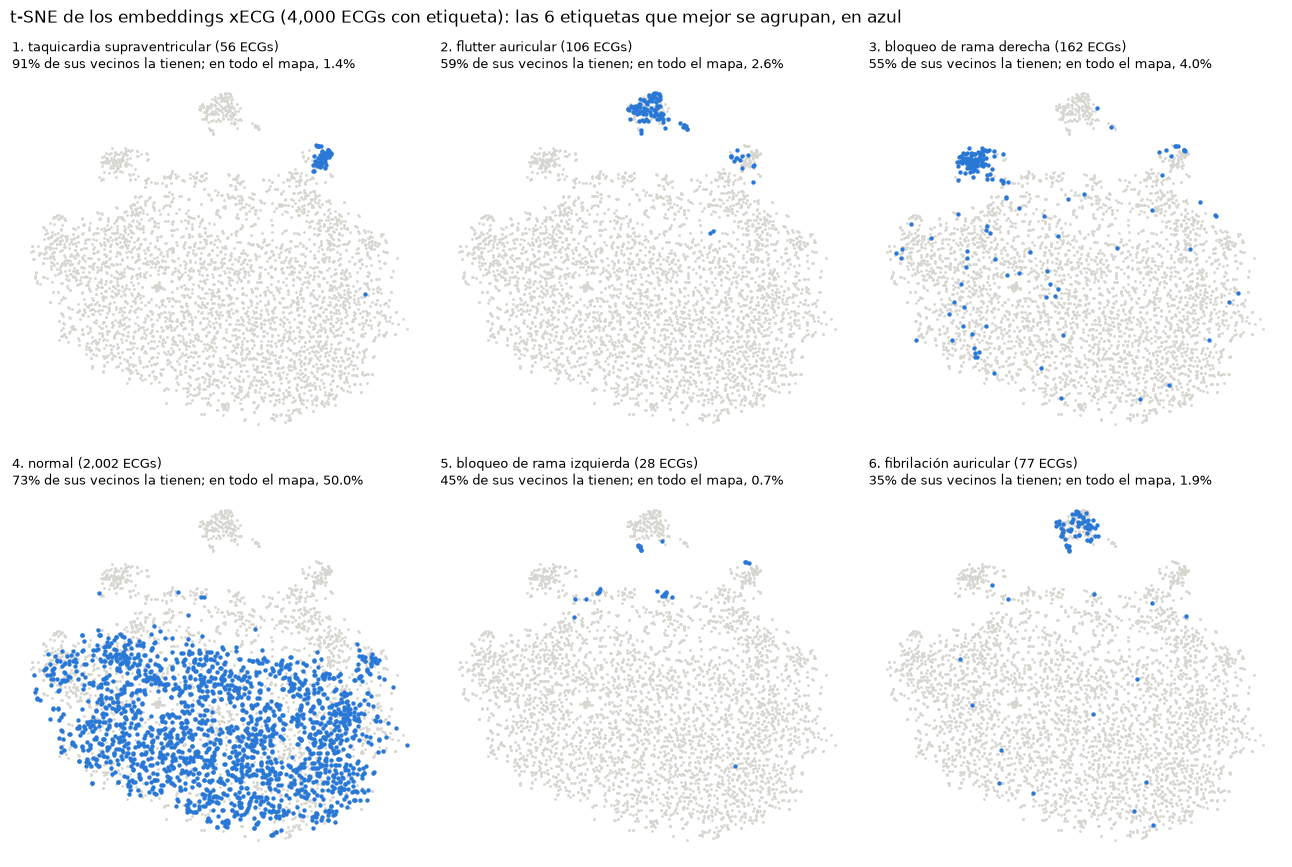

,ECGs en el mapa,% en todo el mapa,% de sus vecinos que también la tienen,veces más que en todo el mapa,agrupación
etiqueta,,,,,
taquicardia supraventricular,56,1.4,90.5,64.7,0.90
flutter auricular,106,2.6,58.9,22.2,0.58
bloqueo de rama derecha,162,4.0,54.8,13.5,0.53
normal,2002,50.0,72.7,1.5,0.45
bloqueo de rama izquierda,28,0.7,44.6,63.8,0.44
fibrilación auricular,77,1.9,35.1,18.2,0.34
onda T anormal,327,8.2,29.5,3.6,0.23
bloqueo fascicular anterior izquierdo,51,1.3,22.2,17.4,0.21
extrasístole ventricular,119,3.0,23.3,7.8,0.21


In [13]:
# Mapa de los embeddings: t-SNE acomoda en un plano los 4,000 ECGs con etiqueta (2,000 de entrenamiento y 2,000 de validación),
# cerca los que tienen embeddings parecidos. Los ejes no tienen unidades: solo importa qué queda cerca de qué.
from sklearn.manifold import TSNE
from sklearn.neighbors import NearestNeighbors

VECINOS_MAPA = 10            # vecinos con los que se mide qué tan juntos quedan los ECGs de una etiqueta
MIN_CASOS_MAPA = 20          # se miden las etiquetas con al menos estos ECGs en el mapa
PANELES = 6                  # etiquetas que se dibujan: las que mejor se agrupan
REDONDEO_MAPA = {"% en todo el mapa": 1, "% de sus vecinos que también la tienen": 1, "veces más que en todo el mapa": 1, "agrupación": 2}


def agrupar(tiene: pd.DataFrame, vecinos: np.ndarray, tiene_vecinos: pd.DataFrame | None = None) -> pd.DataFrame:
    """Por etiqueta: qué % de los vecinos de sus ECGs también la tiene, contra el % que la tiene en todo el mapa.

    `vecinos` son filas de `tiene_vecinos`, los ECGs entre los que se buscan; si no se da, son los mismos de `tiene`.
    Agrupación: 0 = sus vecinos la tienen igual que el resto del mapa (como al azar); 1 = todos sus vecinos la tienen.
    """
    T = tiene.to_numpy()
    V = T if tiene_vecinos is None else tiene_vecinos[tiene.columns].to_numpy()
    tabla = pd.DataFrame({"ECGs en el mapa": T.sum(axis=0),
                          "% en todo el mapa": 100 * V.mean(axis=0),
                          "% de sus vecinos que también la tienen": [100 * V[vecinos[T[:, j] == 1], j].mean() for j in range(T.shape[1])]},
                         index=tiene.columns)
    tabla["veces más que en todo el mapa"] = tabla["% de sus vecinos que también la tienen"] / tabla["% en todo el mapa"]
    tabla["agrupación"] = (tabla["% de sus vecinos que también la tienen"] - tabla["% en todo el mapa"]) / (100 - tabla["% en todo el mapa"])
    return tabla.sort_values("agrupación", ascending=False)


def dibujar_mapa(plano: np.ndarray, tiene: pd.DataFrame, agrupacion: pd.DataFrame, titulo: str, consultas: np.ndarray | None = None) -> None:
    """Un panel por cada una de las PANELES etiquetas que mejor se agrupan: en azul sus ECGs, en gris el resto.

    Con `consultas` (True en los ECGs que buscan vecinos en el banco), los del banco con la etiqueta van en naranja.
    """
    referencia = "en todo el mapa" if consultas is None else "en el banco"
    fig, ejes = plt.subplots(2, 3, figsize=(13, 8.8), sharex=True, sharey=True)
    for lugar, (ax, nombre) in enumerate(zip(ejes.flat, agrupacion.index[:PANELES]), start=1):
        marcados = tiene[nombre].to_numpy() == 1
        medida = agrupacion.loc[nombre]
        ax.scatter(*plano[~marcados].T, s=4, color="#d6d5d0", linewidths=0)
        if consultas is None:
            ax.scatter(*plano[marcados].T, s=10, color="#2a78d6", linewidths=0)
        else:
            ax.scatter(*plano[marcados & ~consultas].T, s=10, color="#eb6834", linewidths=0, label="banco")
            ax.scatter(*plano[marcados & consultas].T, s=10, color="#2a78d6", linewidths=0, label="validación")
        ax.set_title(f"{lugar}. {nombre} ({int(medida['ECGs en el mapa']):,} ECGs{'' if consultas is None else ' de validación'})\n{medida['% de sus vecinos que también la tienen']:.0f}% de sus vecinos la tienen; "
                     f"{referencia}, {medida['% en todo el mapa']:.1f}%", loc="left", fontsize=9.5)
        ax.set_xticks([])
        ax.set_yticks([])
        for borde in ax.spines.values():
            borde.set_visible(False)
    if consultas is not None:
        ejes.flat[0].legend(frameon=False, fontsize=8, loc="lower left", markerscale=2)
    fig.suptitle(titulo, x=0.01, ha="left")
    plt.tight_layout()
    plt.show()


en_mapa = np.concatenate([etiquetados, validacion])
plano = TSNE(n_components=2, metric="cosine", init="pca", random_state=0).fit_transform(np.vstack([E_banco, E_val]))
lista_mapa = ecgs.loc[en_mapa, "cardiopatias"].str.split("; ").explode().dropna()
tiene = pd.crosstab(lista_mapa.index.to_numpy(), lista_mapa.to_numpy()).reindex(en_mapa, fill_value=0).clip(upper=1)
tiene.insert(0, "normal", (particion.loc[en_mapa, "y"] == 0).astype(int).to_numpy())
tiene = tiene.loc[:, tiene.sum() >= MIN_CASOS_MAPA]

# Los vecinos se buscan en el plano: la agrupación describe lo que se ve en el dibujo
_, vecinos = NearestNeighbors(n_neighbors=VECINOS_MAPA + 1).fit(plano).kneighbors(plano)
agrupacion = agrupar(tiene, vecinos[:, 1:])                                       # sin el propio ECG
dibujar_mapa(plano, tiene, agrupacion,
             f"t-SNE de los embeddings xECG ({len(en_mapa):,} ECGs con etiqueta): las {PANELES} etiquetas que mejor se agrupan, en azul")
agrupacion.rename_axis("etiqueta").round(REDONDEO_MAPA)

## 4. Banco de memoria

Los embeddings de los 2,000 ECGs con etiqueta, cada uno con su clase y sus cardiopatías: es todo lo que el modelo sabe de
etiquetas. Una cardiopatía se modela por separado solo si tiene al menos `MIN_EJEMPLOS` ejemplos en el banco.

In [14]:
MIN_EJEMPLOS = 5            # ejemplos en el banco para modelar una cardiopatía por separado

lista = ecgs["cardiopatias"].str.split("; ").explode().dropna()
Y = pd.crosstab(lista.index.to_numpy(), lista.to_numpy()).reindex(ecgs.index, fill_value=0).clip(upper=1)   # ECGs × 43
ejemplos = Y.loc[etiquetados].sum().sort_values(ascending=False)
modeladas = ejemplos.index[ejemplos >= MIN_EJEMPLOS].tolist()

# Etiquetas del banco: la clase ("cualquier cardiopatía") y una columna por cardiopatía modelada
etiquetas = pd.concat([particion["y"].rename("cualquier cardiopatía"), Y[modeladas]], axis=1)
L_banco = etiquetas.loc[etiquetados].to_numpy(dtype=np.float32)

print(f"Banco: {len(etiquetados):,} ECGs ({int(L_banco[:, 0].sum()):,} con cardiopatía) × {E_banco.shape[1]} números")
print(f"Cardiopatías modeladas por separado: {len(modeladas)} de {Y.shape[1]} (al menos {MIN_EJEMPLOS} ejemplos en el banco)")
pd.DataFrame({"ejemplos en el banco": ejemplos, "casos en validación": Y.loc[validacion, ejemplos.index].sum(),
              "se modela": ejemplos >= MIN_EJEMPLOS}).rename_axis("cardiopatía")

Banco: 2,000 ECGs (1,000 con cardiopatía) × 1024 números
Cardiopatías modeladas por separado: 38 de 43 (al menos 5 ejemplos en el banco)


,ejemplos en el banco,casos en validación,se modela
cardiopatía,,,
onda T anormal,175,152,True
cambios del segmento ST,138,132,True
anomalía inespecífica ST-T,89,98,True
bloqueo de rama derecha,77,85,True
hipertrofia ventricular izquierda,71,79,True
QRS anormal,65,68,True
extrasístole ventricular,62,57,True
depresión del ST,57,60,True
onda T invertida,56,52,True


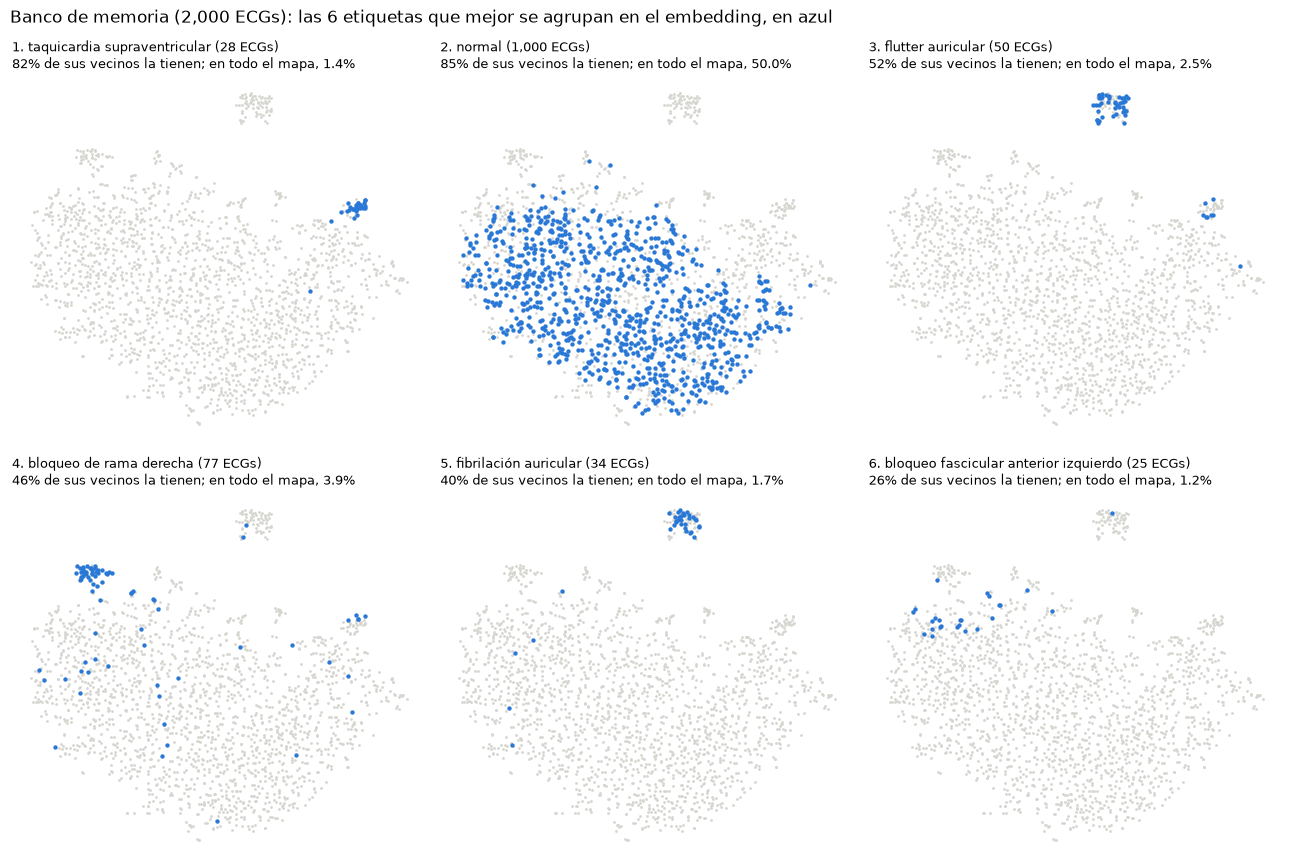

,ECGs en el mapa,% en todo el mapa,% de sus vecinos que también la tienen,veces más que en todo el mapa,agrupación
etiqueta,,,,,
taquicardia supraventricular,28,1.4,81.8,58.4,0.82
normal,1000,50.0,84.6,1.7,0.69
flutter auricular,50,2.5,51.6,20.6,0.50
bloqueo de rama derecha,77,3.8,46.1,12.0,0.44
fibrilación auricular,34,1.7,39.7,23.4,0.39
bloqueo fascicular anterior izquierdo,25,1.2,26.0,20.8,0.25
bloqueo AV de primer grado,44,2.2,23.0,10.4,0.21
extrasístole ventricular,62,3.1,23.1,7.4,0.21
onda T anormal,175,8.8,23.7,2.7,0.16


In [15]:
# Mapa del banco: sus 2,000 ECGs. Aquí los vecinos se buscan en los 1024 números del embedding, con coseno, como en el k-NN
# de la sección 5; el t-SNE solo sirve para dibujarlo.
def con_normal(filas: np.ndarray) -> pd.DataFrame:
    """Etiquetas de esos ECGs para los mapas: normal y cada cardiopatía modelada."""
    tabla = etiquetas.loc[filas].drop(columns="cualquier cardiopatía")
    tabla.insert(0, "normal", 1 - etiquetas.loc[filas, "cualquier cardiopatía"])
    return tabla


tiene_banco = con_normal(etiquetados)
tiene_banco = tiene_banco.loc[:, tiene_banco.sum() >= MIN_CASOS_MAPA]

unitarios_banco = E_banco / np.linalg.norm(E_banco, axis=1, keepdims=True)
similitud_banco = unitarios_banco @ unitarios_banco.T
np.fill_diagonal(similitud_banco, -np.inf)                                        # sin el propio ECG
agrupacion_banco = agrupar(tiene_banco, np.argsort(-similitud_banco, axis=1)[:, :VECINOS_MAPA])

plano_banco = TSNE(n_components=2, metric="cosine", init="pca", random_state=0).fit_transform(E_banco)
dibujar_mapa(plano_banco, tiene_banco, agrupacion_banco,
             f"Banco de memoria ({len(etiquetados):,} ECGs): las {PANELES} etiquetas que mejor se agrupan en el embedding, en azul")
agrupacion_banco.rename_axis("etiqueta").round(REDONDEO_MAPA)

## 5. Consultar el banco en validación

Dos formas de usar el banco con un ECG nuevo:
- **k-NN:** votan los `k` ECGs del banco más parecidos (coseno), y vota más el más parecido.
- **Prototipo:** coseno con el promedio de los ECGs que tienen la etiqueta menos coseno con el promedio de los que no.

`k` se elige en validación con el AUROC de "cualquier cardiopatía". Las cardiopatías se miden solo si tienen al menos
`MIN_CASOS_VAL` casos en validación.

In [16]:
from sklearn.metrics import average_precision_score, roc_auc_score, roc_curve

K_CANDIDATOS = (5, 10, 20, 50, 100, 200, 500)
TEMPERATURA = 0.07           # más chica: el vecino más parecido pesa todavía más
MIN_CASOS_VAL = 20


def unitario(e: np.ndarray) -> np.ndarray:
    return e / np.linalg.norm(e, axis=1, keepdims=True)


def knn(E_consulta: np.ndarray, k: int) -> pd.DataFrame:
    """Puntaje de cada etiqueta: votos de los k ECGs del banco más parecidos, pesados por su coseno."""
    similitud = unitario(E_consulta) @ unitario(E_banco).T
    cercanos = np.argsort(-similitud, axis=1)[:, :k]
    coseno = np.take_along_axis(similitud, cercanos, axis=1)
    peso = np.zeros_like(similitud)
    np.put_along_axis(peso, cercanos, np.exp((coseno - coseno[:, :1]) / TEMPERATURA), axis=1)
    return pd.DataFrame(peso @ L_banco / peso.sum(axis=1, keepdims=True), columns=etiquetas.columns)


def prototipo(E_consulta: np.ndarray) -> pd.DataFrame:
    """Coseno con el promedio de los ECGs con cada etiqueta menos coseno con el promedio de los que no la tienen."""
    banco, consulta = unitario(E_banco), unitario(E_consulta)
    con, sin = unitario(L_banco.T @ banco), unitario((1 - L_banco).T @ banco)
    return pd.DataFrame(consulta @ con.T - consulta @ sin.T, columns=etiquetas.columns)


def aurocs(objetivo: pd.DataFrame, puntajes: pd.DataFrame, columnas: list[str]) -> pd.Series:
    """AUROC de cada etiqueta de `columnas`."""
    return pd.Series({c: roc_auc_score(objetivo[c].to_numpy(), puntajes[c].to_numpy()) for c in columnas})


objetivo_val = etiquetas.loc[validacion]
medibles = [c for c in modeladas if objetivo_val[c].sum() >= MIN_CASOS_VAL]
consultas_banco = {f"k-NN, k = {k}": knn(E_val, k) for k in K_CANDIDATOS} | {"prototipo": prototipo(E_val)}
eleccion = pd.DataFrame([{"cualquier cardiopatía": aurocs(objetivo_val, p, ["cualquier cardiopatía"]).iloc[0],
                         f"macro de {len(medibles)} cardiopatías": aurocs(objetivo_val, p, medibles).mean()}
                         for p in consultas_banco.values()]).set_axis(list(consultas_banco))
k_elegido = K_CANDIDATOS[int(np.argmax(eleccion["cualquier cardiopatía"].iloc[:len(K_CANDIDATOS)]))]
print(f"k elegido en validación: {k_elegido}")
eleccion.rename_axis("AUROC en validación").round(3)

k elegido en validación: 100


,cualquier cardiopatía,macro de 29 cardiopatías
AUROC en validación,,
"k-NN, k = 5",0.878,0.709
"k-NN, k = 10",0.895,0.743
"k-NN, k = 20",0.906,0.793
"k-NN, k = 50",0.911,0.840
"k-NN, k = 100",0.911,0.870
"k-NN, k = 200",0.911,0.880
"k-NN, k = 500",0.907,0.888
prototipo,0.871,0.886


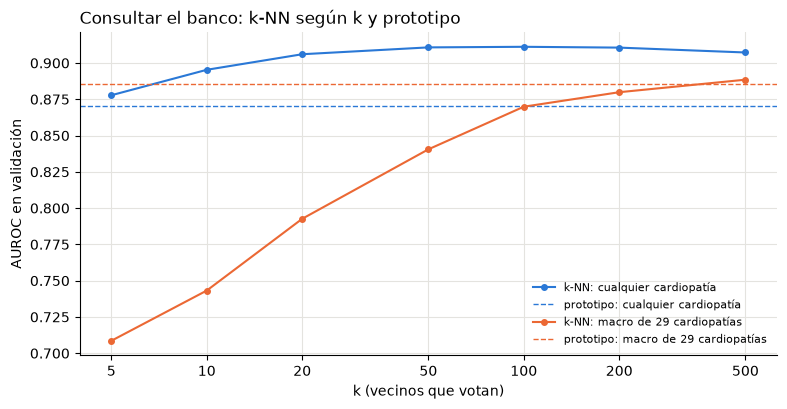

In [17]:
# AUROC del k-NN según k; las líneas punteadas son el prototipo
fig, ax = plt.subplots(figsize=(9, 4.2))
for columna, color in zip(eleccion.columns, ["#2a78d6", "#eb6834"]):
    ax.plot(K_CANDIDATOS, eleccion[columna].iloc[:len(K_CANDIDATOS)], marker="o", markersize=4, color=color, label=f"k-NN: {columna}")
    ax.axhline(eleccion.loc["prototipo", columna], color=color, linestyle="--", linewidth=1, label=f"prototipo: {columna}")
ax.set_xscale("log")
ax.set_xticks(K_CANDIDATOS, [str(k) for k in K_CANDIDATOS])
ax.minorticks_off()
ax.set(xlabel="k (vecinos que votan)", ylabel="AUROC en validación")
ax.set_title("Consultar el banco: k-NN según k y prototipo", loc="left")
ax.grid(color="#e4e3df", linewidth=0.8)
ax.set_axisbelow(True)
ax.legend(frameon=False, fontsize=8, loc="lower right")
for borde in ["top", "right"]:
    ax.spines[borde].set_visible(False)
plt.show()

In [18]:
# AUROC de cada etiqueta en validación con el mejor k-NN y con el prototipo
por_cardiopatia_banco = pd.DataFrame({nombre: aurocs(objetivo_val, consultas_banco[consulta], ["cualquier cardiopatía", *medibles])
                                      for nombre, consulta in [(f"k-NN (k = {k_elegido})", f"k-NN, k = {k_elegido}"), ("prototipo", "prototipo")]})
por_cardiopatia_banco.rename_axis("etiqueta").rename_axis(columns="AUROC en validación").round(3)

AUROC en validación,k-NN (k = 100),prototipo
etiqueta,,
cualquier cardiopatía,0.911,0.871
onda T anormal,0.900,0.859
cambios del segmento ST,0.820,0.781
anomalía inespecífica ST-T,0.861,0.845
bloqueo de rama derecha,0.938,0.923
hipertrofia ventricular izquierda,0.844,0.858
QRS anormal,0.793,0.776
extrasístole ventricular,0.863,0.918
depresión del ST,0.852,0.845


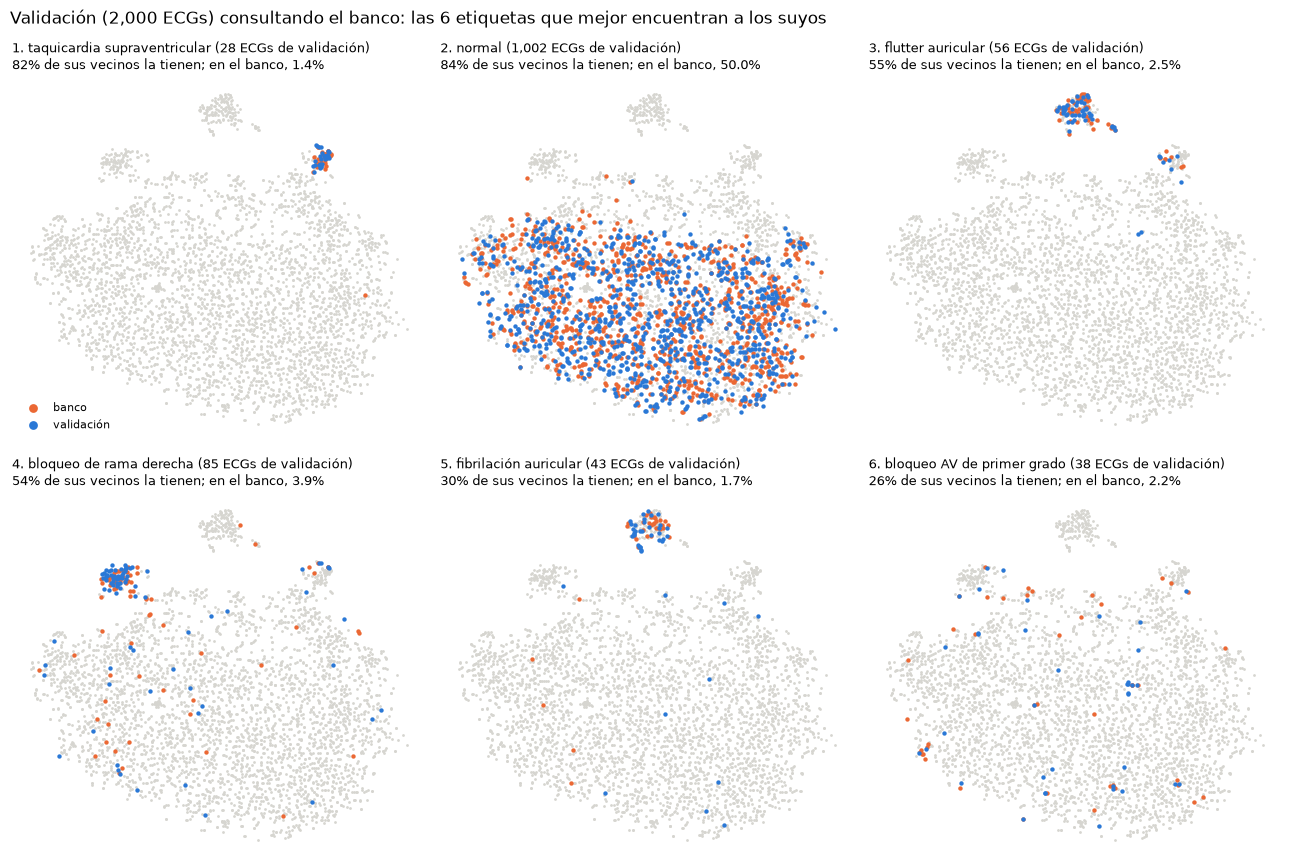

,ECGs de validación,% en el banco,% de sus vecinos del banco que la tienen,veces más que en el banco,agrupación
etiqueta,,,,,
taquicardia supraventricular,28,1.4,81.8,58.4,0.82
normal,1002,50.0,84.3,1.7,0.69
flutter auricular,56,2.5,54.8,21.9,0.54
bloqueo de rama derecha,85,3.8,54.4,14.1,0.53
fibrilación auricular,43,1.7,30.2,17.8,0.29
bloqueo AV de primer grado,38,2.2,26.1,11.8,0.24
bloqueo fascicular anterior izquierdo,26,1.2,23.5,18.8,0.22
extrasístole ventricular,57,3.1,22.5,7.2,0.20
onda T anormal,152,8.8,26.4,3.0,0.19


In [19]:
# Mapa de la consulta: cada ECG de validación busca sus 10 vecinos en el banco, en los 1024 números del embedding y con
# coseno, como el k-NN (aquí todos los vecinos valen igual). El dibujo es el t-SNE de la sección 3.
tiene_val = con_normal(validacion)
tiene_val = tiene_val.loc[:, tiene_val.sum() >= MIN_CASOS_MAPA]
vecinos_val = np.argsort(-(unitario(E_val) @ unitarios_banco.T), axis=1)[:, :VECINOS_MAPA]
agrupacion_val = agrupar(tiene_val, vecinos_val, con_normal(etiquetados))

dibujar_mapa(plano, tiene, agrupacion_val, f"Validación ({len(validacion):,} ECGs) consultando el banco: las {PANELES} etiquetas que mejor "
             "encuentran a los suyos", consultas=np.isin(en_mapa, validacion))
agrupacion_val.rename_axis("etiqueta").round(REDONDEO_MAPA).rename(columns={
    "ECGs en el mapa": "ECGs de validación", "% en todo el mapa": "% en el banco",
    "% de sus vecinos que también la tienen": "% de sus vecinos del banco que la tienen", "veces más que en todo el mapa": "veces más que en el banco"})

## 6. Comparación: regresión logística por cardiopatía

Desde aquí se entrena un clasificador, con las etiquetas de los 2,000 ECGs del banco, sobre los embeddings congelados.

Una regresión logística por etiqueta ("cualquier cardiopatía" y cada cardiopatía modelada), entrenada con los 2,000 del
banco: cada una da la probabilidad de esa etiqueta a partir de los 1024 números del embedding.

In [20]:
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

C_CANDIDATOS = (0.001, 0.01, 0.1, 1.0, 10.0)


def entrenar(entrada_banco: np.ndarray, C: float, columnas: list[str]) -> dict:
    """Una regresión logística por etiqueta, entrenada con el banco; cada número de la entrada se estandariza antes."""
    return {c: make_pipeline(StandardScaler(), LogisticRegression(C=C, max_iter=5000)).fit(entrada_banco, etiquetas.loc[etiquetados, c])
            for c in columnas}


def puntuar(modelos_etiqueta: dict, entrada: np.ndarray) -> pd.DataFrame:
    return pd.DataFrame({c: m.predict_proba(entrada)[:, 1] for c, m in modelos_etiqueta.items()})


def elegir_C(entrada_banco: np.ndarray, entrada_val: np.ndarray) -> tuple[float, pd.Series]:
    """El C con mejor AUROC de "cualquier cardiopatía" en validación."""
    auroc = pd.Series({C: aurocs(objetivo_val, puntuar(entrenar(entrada_banco, C, ["cualquier cardiopatía"]), entrada_val),
                                 ["cualquier cardiopatía"]).iloc[0] for C in C_CANDIDATOS})
    return auroc.idxmax(), auroc


C_embeddings, auroc_por_C = elegir_C(E_banco, E_val)
modelos_embeddings = entrenar(E_banco, C_embeddings, etiquetas.columns.tolist())
por_cardiopatia = aurocs(objetivo_val, puntuar(modelos_embeddings, E_val), ["cualquier cardiopatía", *medibles])
display(auroc_por_C.rename("AUROC de cualquier cardiopatía en validación").rename_axis("C").to_frame().round(3))
print(f"C elegido: {C_embeddings} | AUROC macro de {len(medibles)} cardiopatías: {por_cardiopatia[medibles].mean():.3f}")
por_cardiopatia.rename("AUROC en validación").rename_axis("etiqueta").to_frame().round(3)

,AUROC de cualquier cardiopatía en validación
C,
0.001,0.926
0.010,0.927
0.100,0.921
1.000,0.910
10.000,0.902


C elegido: 0.01 | AUROC macro de 29 cardiopatías: 0.924


,AUROC en validación
etiqueta,
cualquier cardiopatía,0.927
onda T anormal,0.917
cambios del segmento ST,0.853
anomalía inespecífica ST-T,0.864
bloqueo de rama derecha,0.978
hipertrofia ventricular izquierda,0.936
QRS anormal,0.877
extrasístole ventricular,0.945
depresión del ST,0.878


## 7. Comparación: embeddings + 111 características

La misma regresión logística con tres entradas: los 1024 números del embedding, esos 1024 más las 111 características
(1135 números) y solo las 111. `C` se elige en validación para cada entrada.

In [21]:
def especificidad(y: np.ndarray, p: np.ndarray, sensibilidad: float) -> float:
    """La especificidad más alta entre los umbrales que llegan a esa sensibilidad."""
    fpr, tpr, _ = roc_curve(y, p)
    return 1 - fpr[tpr >= sensibilidad].min()


def medidas(y: np.ndarray, p: np.ndarray) -> dict:
    return {"AUROC": roc_auc_score(y, p), "AUPRC": average_precision_score(y, p),
            "especificidad con 95% de sensibilidad": especificidad(y, p, 0.95), "con 99%": especificidad(y, p, 0.99)}


X_banco, X_val = caracteristicas.loc[etiquetados].to_numpy(), caracteristicas.loc[validacion].to_numpy()
entradas = {"solo embeddings": (E_banco, E_val),
            "embeddings + 111": (np.hstack([E_banco, X_banco]), np.hstack([E_val, X_val])),
            "solo 111": (X_banco, X_val)}
modelos, C_elegido = {"solo embeddings": modelos_embeddings}, {"solo embeddings": C_embeddings}
for nombre, (entrada_banco, entrada_val) in entradas.items():
    if nombre not in modelos:
        C_elegido[nombre], _ = elegir_C(entrada_banco, entrada_val)
        modelos[nombre] = entrenar(entrada_banco, C_elegido[nombre], etiquetas.columns.tolist())
puntajes = {nombre: puntuar(modelos[nombre], entrada_val) for nombre, (_, entrada_val) in entradas.items()}

y_val = objetivo_val["cualquier cardiopatía"].to_numpy()
display(pd.DataFrame([{"entrada": nombre, "números por ECG": entradas[nombre][0].shape[1], "C": C_elegido[nombre],
                       **medidas(y_val, p["cualquier cardiopatía"].to_numpy()),
                       f"AUROC macro de {len(medibles)} cardiopatías": aurocs(objetivo_val, p, medibles).mean()}
                      for nombre, p in puntajes.items()]).set_index("entrada").round(3))

,números por ECG,C,AUROC,AUPRC,especificidad con 95% de sensibilidad,con 99%,AUROC macro de 29 cardiopatías
entrada,,,,,,,
solo embeddings,1024,0.01,0.927,0.938,0.601,0.155,0.924
embeddings + 111,1135,0.01,0.928,0.939,0.612,0.174,0.926
solo 111,111,1.00,0.882,0.898,0.409,0.122,0.861


## 8. Matrices de confusión

| | El modelo dice cardiopatía: va a revisión | El modelo dice normal: se descarta |
|---|---|---|
| **Tiene cardiopatía** | Verdadero positivo: se detecta | **Falso negativo: se escapa** |
| **Es normal** | Falso positivo: falsa alarma | Verdadero negativo: se descarta bien |

F1 y F2 juntan dos cosas en un número de 0 a 1: la sensibilidad (de los que tienen cardiopatía, cuántos van a revisión) y la
precisión (de los que van a revisión, cuántos sí tienen cardiopatía). F2 le da más peso a la
sensibilidad.

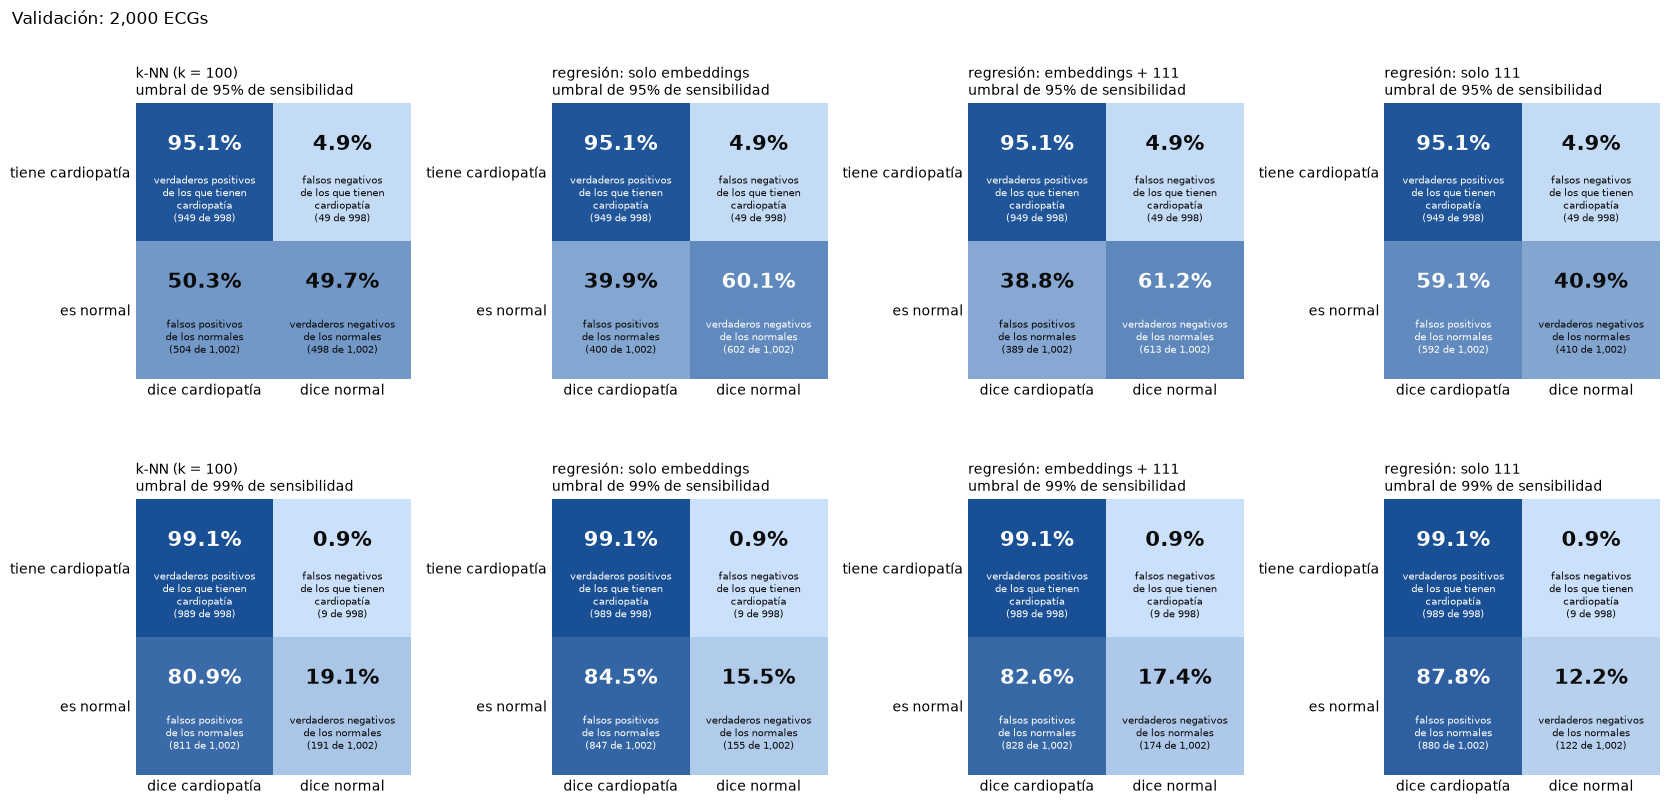

cardiopatías que se escapan (%)  \
umbral modelo                                                         
95%    k-NN (k = 100)                                           4.9   
       regresión: solo embeddings                               4.9   
       regresión: embeddings + 111                              4.9   
       regresión: solo 111                                      4.9   
99%    k-NN (k = 100)                                           0.9   
       regresión: solo embeddings                               0.9   
       regresión: embeddings + 111                              0.9   
       regresión: solo 111                                      0.9   

                                    normales a revisión (%)     F1     F2  
umbral modelo                                                              
95%    k-NN (k = 100)                                  50.3  0.774  0.871  
       regresión: solo embeddings                      39.9  0.809  0.888  
       regresión: embeddings + 111                     38.8  0.812  0.890  
       regresión: solo 111                             59.1  0.748  0.858  
99%    k-NN (k = 100)                                  80.9  0.707  0.854  
       regresión: solo embeddings                      84.5  0.698  0.848  
       regresión: embeddings + 111                     82.6  0.703  0.851  
       regresión: solo 111                             87.8  0.690  0.844

In [22]:
from matplotlib.colors import LinearSegmentedColormap

SENSIBILIDADES = (0.95, 0.99)
REDONDEO = {"cardiopatías que se escapan (%)": 1, "normales a revisión (%)": 1, "F1": 3, "F2": 3}   # columnas que se muestran

CASILLAS = [["verdaderos positivos", "falsos negativos"], ["falsos positivos", "verdaderos negativos"]]
DE_FILA = ["de los que tienen\ncardiopatía", "de los normales"]
AZUL = LinearSegmentedColormap.from_list("azul", ["#cde2fb", "#184f95"])


def umbral(y: np.ndarray, p: np.ndarray, sensibilidad: float) -> float:
    """El umbral más alto que llega a esa sensibilidad: un puntaje igual o mayor va a revisión."""
    _, tpr, cortes = roc_curve(y, p)
    return cortes[np.argmax(tpr >= sensibilidad)]


def matriz(y: np.ndarray, p: np.ndarray, u: float) -> np.ndarray:
    alerta = p >= u
    return np.array([[(alerta & (y == 1)).sum(), (~alerta & (y == 1)).sum()],
                     [(alerta & (y == 0)).sum(), (~alerta & (y == 0)).sum()]])


def tabla_matrices(y: np.ndarray, binarios: dict) -> pd.DataFrame:
    """Por modelo y umbral: % que se escapan, % de normales a revisión, F1, F2 y las cuatro casillas."""
    tabla = []
    for s in SENSIBILIDADES:
        for modelo, p in binarios.items():
            cuentas = matriz(y, p, umbrales[(modelo, s)])
            porcentaje = 100 * cuentas / cuentas.sum(axis=1, keepdims=True)
            vp, fn, fp = cuentas[0, 0], cuentas[0, 1], cuentas[1, 0]
            tabla.append({"modelo": modelo, "umbral": f"{s:.0%}", "cardiopatías que se escapan (%)": porcentaje[0, 1],
                          "normales a revisión (%)": porcentaje[1, 0], "F1": 2 * vp / (2 * vp + fp + fn), "F2": 5 * vp / (5 * vp + 4 * fn + fp),
                          **dict(zip(sum(CASILLAS, []), cuentas.flatten()))})
    return pd.DataFrame(tabla)


def dibujar_matrices(y: np.ndarray, binarios: dict, titulo: str) -> None:
    """Una matriz por modelo y umbral: el porcentaje de su fila en grande y la cantidad en chico. Con un solo modelo, una fila."""
    filas, columnas = (1, len(SENSIBILIDADES)) if len(binarios) == 1 else (len(SENSIBILIDADES), len(binarios))
    fig, ejes = plt.subplots(filas, columnas, figsize=(4.2 * columnas, 4.2 * filas), squeeze=False)
    for ax, (s, modelo) in zip(ejes.flat, [(s, modelo) for s in SENSIBILIDADES for modelo in binarios]):
        cuentas = matriz(y, binarios[modelo], umbrales[(modelo, s)])
        porcentaje = 100 * cuentas / cuentas.sum(axis=1, keepdims=True)
        ax.imshow(porcentaje, cmap=AZUL, vmin=0, vmax=100)
        for i in range(2):
            for j in range(2):
                color = "#fcfcfb" if porcentaje[i, j] > 55 else "#0b0b0b"
                ax.text(j, i - 0.2, f"{porcentaje[i, j]:.1f}%", ha="center", va="center", fontsize=15, fontweight="bold", color=color)
                ax.text(j, i + 0.2, f"{CASILLAS[i][j]}\n{DE_FILA[i]}\n({cuentas[i, j]:,} de {cuentas[i].sum():,})",
                        ha="center", va="center", fontsize=7.5, color=color)
        ax.set_xticks([0, 1], ["dice cardiopatía", "dice normal"])
        ax.set_yticks([0, 1], ["tiene cardiopatía", "es normal"])
        ax.tick_params(length=0)
        for borde in ax.spines.values():
            borde.set_visible(False)
        ax.set_title(f"{modelo}\numbral de {s:.0%} de sensibilidad", loc="left", fontsize=10)
    fig.suptitle(titulo, x=0.01, ha="left")
    plt.tight_layout()
    plt.show()


def mostrar_matrices(y: np.ndarray, binarios: dict, titulo: str) -> pd.DataFrame:
    """Dibuja las matrices de todos los modelos y devuelve su tabla."""
    dibujar_matrices(y, binarios, titulo)
    return tabla_matrices(y, binarios)


puntajes_val = {f"k-NN (k = {k_elegido})": knn(E_val, k_elegido)} | {f"regresión: {n}": p for n, p in puntajes.items()}
binarios_val = {m: p["cualquier cardiopatía"].to_numpy() for m, p in puntajes_val.items()}
umbrales = {(m, s): umbral(y_val, p, s) for m, p in binarios_val.items() for s in SENSIBILIDADES}
matrices_val = mostrar_matrices(y_val, binarios_val, f"Validación: {len(y_val):,} ECGs")
matrices_val.to_csv(CARPETA / "matrices_confusion_val.csv", index=False)
matrices_val.set_index(["umbral", "modelo"])[list(REDONDEO)].round(REDONDEO)

## 9. Prueba final

Con los modelos y umbrales elegidos en validación, sin entrenar ni elegir nada más:
- **Test del v3**: los ECGs de prueba de la partición (1.1).
- **SPH** (Shandong) con la clasificación del Avance 5: **positivo** si tiene algún código de infarto, ST-T, trastorno de
  conducción o hipertrofia; **normal** si su único código es el 1; los demás quedan fuera.

### 9.1 Datos de prueba

In [23]:
prueba = particion.index[particion["split"] == "test"].to_numpy()
objetivo_test = etiquetas.loc[prueba]
y_test = objetivo_test["cualquier cardiopatía"].to_numpy()
X_test = caracteristicas.loc[prueba].to_numpy()
E_test = embeddings_congelados(senales, prueba)

SPH = Path("../outputs/notebook18_sph_avance5")      # SPH con la clasificación del Avance 5 (notebook 18-ag-sph-clasificacion-avance5)
sph = pd.read_csv(SPH / "sph_evaluados.csv", index_col="ECG_ID")     # positivos y normales que pasaron las revisiones de lectura
senales_sph = np.load(SPH / "senales_sph.npy", mmap_mode="r")         # "posicion": la fila de cada ECG en senales_sph.npy

lista_sph = sph["cardiopatias"].str.split("; ").explode().dropna()
Y_sph = pd.crosstab(lista_sph.index.to_numpy(), lista_sph.to_numpy()).reindex(sph.index, fill_value=0).clip(upper=1)
objetivo_sph = pd.concat([(sph["clase"] == "positivo").astype(int).rename("cualquier cardiopatía"), Y_sph], axis=1)
y_sph = objetivo_sph["cualquier cardiopatía"].to_numpy()
conjuntos = {"SPH menores de 60": (sph["edades"] == "menores de 60").to_numpy(), "SPH todas las edades": np.ones(len(sph), bool)}

# Las 111 con el preprocesamiento ajustado en el entrenamiento del v3 (1.3), y los embeddings con el encoder congelado
primarias_sph = pd.DataFrame([ca2.extract(np.asarray(senales_sph[p, :4800], dtype=np.float32)) for p in sph["posicion"]], index=sph.index)
primarias_sph["implausible"] = primarias_sph["implausible"].fillna("")
X_sph = preprocesador.transform(ca2.derive(primarias_sph)).to_numpy()
E_sph = embeddings_congelados(senales_sph, sph["posicion"].to_numpy())
np.savez_compressed(CARPETA / "embeddings_prueba.npz", prueba=prueba, E_test=E_test, sph=sph.index.to_numpy(), E_sph=E_sph)

entradas_test = {"solo embeddings": E_test, "embeddings + 111": np.hstack([E_test, X_test]), "solo 111": X_test}
entradas_sph = {"solo embeddings": E_sph, "embeddings + 111": np.hstack([E_sph, X_sph]), "solo 111": X_sph}
puntajes_test = {f"k-NN (k = {k_elegido})": knn(E_test, k_elegido)} | {f"regresión: {n}": puntuar(modelos[n], x) for n, x in entradas_test.items()}
puntajes_sph = {f"k-NN (k = {k_elegido})": knn(E_sph, k_elegido)} | {f"regresión: {n}": puntuar(modelos[n], x) for n, x in entradas_sph.items()}

display(pd.DataFrame({"ECGs": [len(prueba)], "con cardiopatía": [int(y_test.sum())], "normales": [int((y_test == 0).sum())]}, index=["test v3"]))
pd.crosstab(sph["clase"], sph["edades"], margins=True, margins_name="total")[["menores de 60", "60 o más", "total"]]

,ECGs,con cardiopatía,normales
test v3,4001,2000,2001


edades,menores de 60,60 o más,total
clase,,,
normal,10879,2677,13556
positivo,3836,3265,7101
total,14715,5942,20657


### 9.2 Resultados en la prueba

AUROC,validación v3,test v3,SPH menores de 60,SPH todas las edades
modelo,,,,
k-NN (k = 100),0.911,0.909,0.888,0.907
regresión: solo embeddings,0.927,0.926,0.908,0.928
regresión: embeddings + 111,0.928,0.928,0.908,0.928
regresión: solo 111,0.882,0.871,0.837,0.866


cardiopatías que se escapan (%)  \
conjunto umbral modelo                                                         
test v3  95%    k-NN (k = 100)                                           5.9   
                regresión: solo embeddings                               6.0   
                regresión: embeddings + 111                              6.2   
                regresión: solo 111                                      6.0   
         99%    k-NN (k = 100)                                           1.5   
                regresión: solo embeddings                               0.6   
                regresión: embeddings + 111                              0.8   
                regresión: solo 111                                      1.3   

                                             normales a revisión (%)     F1  \
conjunto umbral modelo                                                        
test v3  95%    k-NN (k = 100)                                  49.1  0.774   
                regresión: solo embeddings                      41.2  0.799   
                regresión: embeddings + 111                     39.3  0.805   
                regresión: solo 111                             61.3  0.737   
         99%    k-NN (k = 100)                                  80.5  0.706   
                regresión: solo embeddings                      85.2  0.698   
                regresión: embeddings + 111                     82.7  0.704   
                regresión: solo 111                             88.6  0.687   

                                                F2  
conjunto umbral modelo                              
test v3  95%    k-NN (k = 100)               0.866  
                regresión: solo embeddings   0.878  
                regresión: embeddings + 111  0.879  
                regresión: solo 111          0.847  
         99%    k-NN (k = 100)               0.851  
                regresión: solo embeddings   0.850  
                regresión: embeddings + 111  0.852  
                regresión: solo 111          0.840

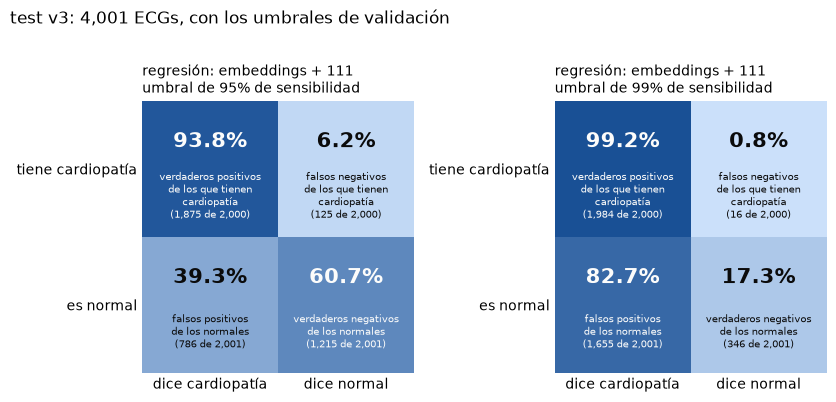

cardiopatías que se escapan (%)  \
conjunto          umbral modelo                                                         
SPH menores de 60 95%    k-NN (k = 100)                                           5.3   
                         regresión: solo embeddings                               6.0   
                         regresión: embeddings + 111                              6.5   
                         regresión: solo 111                                      5.5   
                  99%    k-NN (k = 100)                                           0.9   
                         regresión: solo embeddings                               0.4   
                         regresión: embeddings + 111                              0.7   
                         regresión: solo 111                                      0.8   

                                                      normales a revisión (%)  \
conjunto          umbral modelo                                                 
SPH menores de 60 95%    k-NN (k = 100)                                  53.6   
                         regresión: solo embeddings                      44.5   
                         regresión: embeddings + 111                     43.1   
                         regresión: solo 111                             67.8   
                  99%    k-NN (k = 100)                                  83.2   
                         regresión: solo embeddings                      89.8   
                         regresión: embeddings + 111                     88.3   
                         regresión: solo 111                             93.4   

                                                         F1     F2  
conjunto          umbral modelo                                     
SPH menores de 60 95%    k-NN (k = 100)               0.546  0.732  
                         regresión: solo embeddings   0.587  0.758  
                         regresión: embeddings + 111  0.593  0.760  
                         regresión: solo 111          0.489  0.688  
                  99%    k-NN (k = 100)               0.456  0.674  
                         regresión: solo embeddings   0.438  0.660  
                         regresión: embeddings + 111  0.442  0.663  
                         regresión: solo 111          0.428  0.649

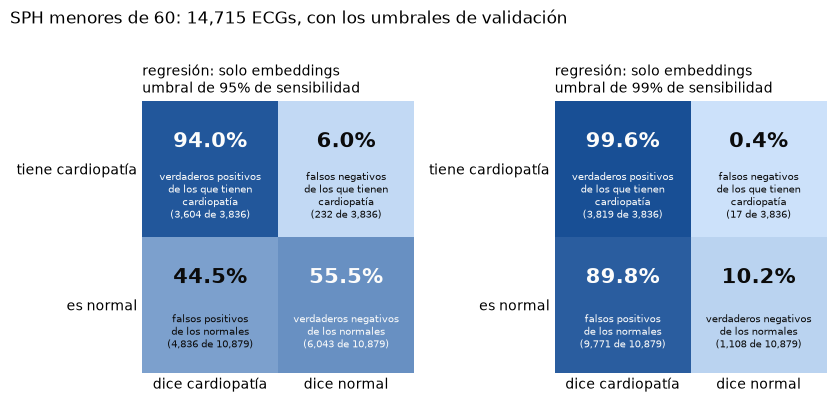

In [24]:
resultados = pd.DataFrame([{"modelo": m, "conjunto": "validación v3", **medidas(y_val, binarios_val[m])} for m in puntajes_val]
                          + [{"modelo": m, "conjunto": "test v3", **medidas(y_test, p["cualquier cardiopatía"].to_numpy())} for m, p in puntajes_test.items()]
                          + [{"modelo": m, "conjunto": nombre, **medidas(y_sph[mascara], p["cualquier cardiopatía"].to_numpy()[mascara])}
                             for m, p in puntajes_sph.items() for nombre, mascara in conjuntos.items()])
resultados.to_csv(CARPETA / "resultados_val_prueba.csv", index=False)
COLUMNAS_PRUEBA = ["validación v3", "test v3", "SPH menores de 60", "SPH todas las edades"]
display(resultados.pivot_table(index="modelo", columns="conjunto", values="AUROC", sort=False)[COLUMNAS_PRUEBA]
        .rename_axis(columns="AUROC").round(3))

# Matrices con los umbrales de validación: la tabla con todos los modelos y el dibujo solo del de mejor AUROC en cada conjunto
menor = conjuntos["SPH menores de 60"]
prueba_binarios = {"test v3": (y_test, {m: p["cualquier cardiopatía"].to_numpy() for m, p in puntajes_test.items()}),
                   "SPH menores de 60": (y_sph[menor], {m: p["cualquier cardiopatía"].to_numpy()[menor] for m, p in puntajes_sph.items()})}
matrices_prueba = []
for nombre, (y, binarios) in prueba_binarios.items():
    tabla = tabla_matrices(y, binarios).assign(conjunto=nombre)
    matrices_prueba.append(tabla)
    display(tabla.set_index(["conjunto", "umbral", "modelo"])[list(REDONDEO)].round(REDONDEO))
    mejor = resultados.query("conjunto == @nombre").set_index("modelo")["AUROC"].idxmax()
    dibujar_matrices(y, {mejor: binarios[mejor]}, f"{nombre}: {len(y):,} ECGs, con los umbrales de validación")
pd.concat(matrices_prueba).to_csv(CARPETA / "matrices_confusion_prueba.csv", index=False)

In [25]:
# AUROC por cardiopatía en la prueba: las modeladas con al menos MIN_CASOS_VAL casos en cada conjunto
medibles_test = [c for c in modeladas if objetivo_test[c].sum() >= MIN_CASOS_VAL]
medibles_sph = [c for c in modeladas if c in Y_sph and Y_sph.loc[menor, c].sum() >= MIN_CASOS_VAL]
for nombre, objetivo, puntajes_conjunto, columnas in [("test v3", objetivo_test, puntajes_test, medibles_test),
                                                      ("SPH menores de 60", objetivo_sph[menor], {m: p[menor] for m, p in puntajes_sph.items()}, medibles_sph)]:
    print(f"AUROC por cardiopatía en {nombre}: {len(columnas)} cardiopatías modeladas con al menos {MIN_CASOS_VAL} casos")
    tabla = pd.DataFrame({m: aurocs(objetivo, p, columnas) for m, p in puntajes_conjunto.items()})
    display(pd.concat([tabla, tabla.mean().rename("macro").to_frame().T]).round(3))

AUROC por cardiopatía en test v3: 34 cardiopatías modeladas con al menos 20 casos


,k-NN (k = 100),regresión: solo embeddings,regresión: embeddings + 111,regresión: solo 111
onda T anormal,0.898,0.900,0.904,0.822
cambios del segmento ST,0.825,0.829,0.830,0.722
anomalía inespecífica ST-T,0.816,0.836,0.836,0.760
bloqueo de rama derecha,0.956,0.973,0.974,0.954
hipertrofia ventricular izquierda,0.855,0.932,0.938,0.906
QRS anormal,0.798,0.899,0.900,0.839
extrasístole ventricular,0.857,0.958,0.966,0.951
depresión del ST,0.863,0.872,0.877,0.849
onda T invertida,0.837,0.861,0.859,0.760
bloqueo incompleto de rama derecha,0.842,0.914,0.921,0.886


AUROC por cardiopatía en SPH menores de 60: 16 cardiopatías modeladas con al menos 20 casos


,k-NN (k = 100),regresión: solo embeddings,regresión: embeddings + 111,regresión: solo 111
onda T anormal,0.912,0.929,0.927,0.831
cambios del segmento ST,0.792,0.855,0.855,0.736
bloqueo de rama derecha,0.992,0.997,0.997,0.977
hipertrofia ventricular izquierda,0.893,0.979,0.982,0.964
extrasístole ventricular,0.942,0.967,0.971,0.964
depresión del ST,0.848,0.871,0.873,0.858
onda T invertida,0.896,0.914,0.912,0.856
bloqueo incompleto de rama derecha,0.790,0.841,0.838,0.734
flutter auricular,0.996,0.998,0.998,0.914
bloqueo AV de primer grado,0.994,0.997,0.997,0.892


## 10. Comparación: gradient boosting

Lo mismo de las secciones 6 a 9, con gradient boosting en vez de regresión logística y dos entradas: solo las 111 y
embeddings + 111. Se entrena con los mismos 2,000 ECGs del banco, sus valores (árboles, tasa y hojas) se eligen en
validación con el AUROC de "cualquier cardiopatía", y en la prueba no se entrena ni se elige nada.

### 10.1 Validación

AUROC de cualquier cardiopatía en validación  solo 111  embeddings + 111
árboles tasa hojas                                                      
100     0.03 7                                   0.909             0.922
             31                                  0.917             0.928
        0.10 7                                   0.918             0.929
             31                                  0.918             0.934
300     0.03 7                                   0.918             0.932
             31                                  0.921             0.936
        0.10 7                                   0.918             0.932
             31                                  0.919             0.936

,AUROC,AUPRC,especificidad con 95% de sensibilidad,con 99%,AUROC macro de 29 cardiopatías
modelo,,,,,
regresión: solo 111,0.882,0.898,0.409,0.122,0.861
regresión: embeddings + 111,0.928,0.939,0.612,0.174,0.926
gradient boosting: solo 111,0.921,0.931,0.534,0.216,0.886
gradient boosting: embeddings + 111,0.936,0.945,0.633,0.254,0.918


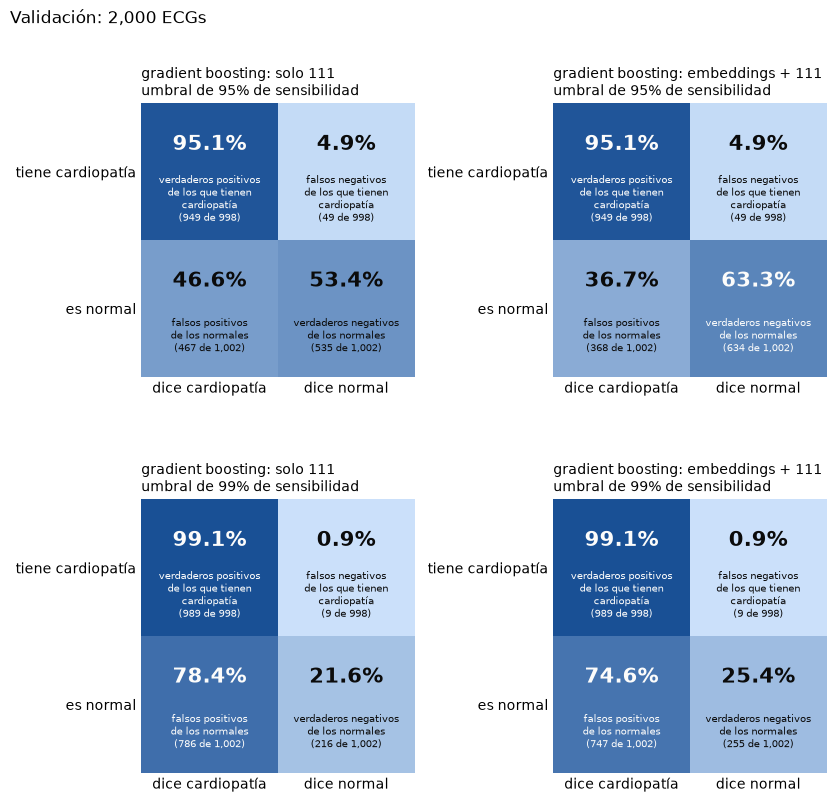

cardiopatías que se escapan (%)  \
umbral modelo                                                                 
95%    regresión: embeddings + 111                                      4.9   
       regresión: solo 111                                              4.9   
       gradient boosting: solo 111                                      4.9   
       gradient boosting: embeddings + 111                              4.9   
99%    regresión: embeddings + 111                                      0.9   
       regresión: solo 111                                              0.9   
       gradient boosting: solo 111                                      0.9   
       gradient boosting: embeddings + 111                              0.9   

                                            normales a revisión (%)     F1  \
umbral modelo                                                                
95%    regresión: embeddings + 111                             38.8  0.812   
       regresión: solo 111                                     59.1  0.748   
       gradient boosting: solo 111                             46.6  0.786   
       gradient boosting: embeddings + 111                     36.7  0.820   
99%    regresión: embeddings + 111                             82.6  0.703   
       regresión: solo 111                                     87.8  0.690   
       gradient boosting: solo 111                             78.4  0.713   
       gradient boosting: embeddings + 111                     74.6  0.723   

                                               F2  
umbral modelo                                      
95%    regresión: embeddings + 111          0.890  
       regresión: solo 111                  0.858  
       gradient boosting: solo 111          0.877  
       gradient boosting: embeddings + 111  0.894  
99%    regresión: embeddings + 111          0.851  
       regresión: solo 111                  0.844  
       gradient boosting: solo 111          0.857  
       gradient boosting: embeddings + 111  0.863

In [26]:
from sklearn.ensemble import HistGradientBoostingClassifier

ARBOLES_GB = (100, 300)      # árboles en total: cada uno corrige lo que fallan los anteriores
TASAS_GB = (0.03, 0.1)       # cuánto pesa cada árbol nuevo
HOJAS_GB = (7, 31)           # hojas por árbol: más hojas, reglas más finas
VALORES_GB = [(a, t, h) for a in ARBOLES_GB for t in TASAS_GB for h in HOJAS_GB]


def entrenar_gb(entrada_banco: np.ndarray, valores: tuple, columnas: list[str]) -> dict:
    """Un gradient boosting por etiqueta, entrenado con el banco."""
    arboles, tasa, hojas = valores
    return {c: HistGradientBoostingClassifier(max_iter=arboles, learning_rate=tasa, max_leaf_nodes=hojas, random_state=0)
            .fit(entrada_banco, etiquetas.loc[etiquetados, c]) for c in columnas}


def elegir_gb(entrada_banco: np.ndarray, entrada_val: np.ndarray) -> tuple[tuple, pd.Series]:
    """Los valores con mejor AUROC de "cualquier cardiopatía" en validación."""
    auroc = pd.Series({v: aurocs(objetivo_val, puntuar(entrenar_gb(entrada_banco, v, ["cualquier cardiopatía"]), entrada_val),
                                 ["cualquier cardiopatía"]).iloc[0] for v in VALORES_GB})
    return auroc.idxmax(), auroc


entradas_gb = {n: entradas[n] for n in ("solo 111", "embeddings + 111")}
valores_gb, busqueda_gb, modelos_gb = {}, {}, {}
for nombre, (entrada_banco, entrada_val) in entradas_gb.items():
    valores_gb[nombre], busqueda_gb[nombre] = elegir_gb(entrada_banco, entrada_val)
    modelos_gb[nombre] = entrenar_gb(entrada_banco, valores_gb[nombre], etiquetas.columns.tolist())
display(pd.DataFrame(busqueda_gb).rename_axis(["árboles", "tasa", "hojas"])
        .rename_axis(columns="AUROC de cualquier cardiopatía en validación").round(3))

puntajes_gb = {f"gradient boosting: {n}": puntuar(modelos_gb[n], entrada_val) for n, (_, entrada_val) in entradas_gb.items()}
comparados = {f"regresión: {n}": puntajes[n] for n in entradas_gb} | puntajes_gb
display(pd.DataFrame([{"modelo": m, **medidas(y_val, p["cualquier cardiopatía"].to_numpy()),
                       f"AUROC macro de {len(medibles)} cardiopatías": aurocs(objetivo_val, p, medibles).mean()}
                      for m, p in comparados.items()]).set_index("modelo").round(3))

binarios_gb_val = {m: p["cualquier cardiopatía"].to_numpy() for m, p in puntajes_gb.items()}
umbrales |= {(m, s): umbral(y_val, p, s) for m, p in binarios_gb_val.items() for s in SENSIBILIDADES}
matrices_gb_val = mostrar_matrices(y_val, binarios_gb_val, f"Validación: {len(y_val):,} ECGs")
matrices_gb_val.to_csv(CARPETA / "matrices_confusion_gb_val.csv", index=False)
filas = matrices_val["modelo"].isin([f"regresión: {n}" for n in entradas_gb])
pd.concat([matrices_val[filas], matrices_gb_val]).sort_values("umbral", kind="stable").set_index(["umbral", "modelo"])[list(REDONDEO)].round(REDONDEO)

### 10.2 Prueba

AUROC,validación v3,test v3,SPH menores de 60,SPH todas las edades
modelo,,,,
regresión: solo 111,0.882,0.871,0.837,0.866
regresión: embeddings + 111,0.928,0.928,0.908,0.928
gradient boosting: solo 111,0.921,0.916,0.899,0.920
gradient boosting: embeddings + 111,0.936,0.931,0.910,0.928


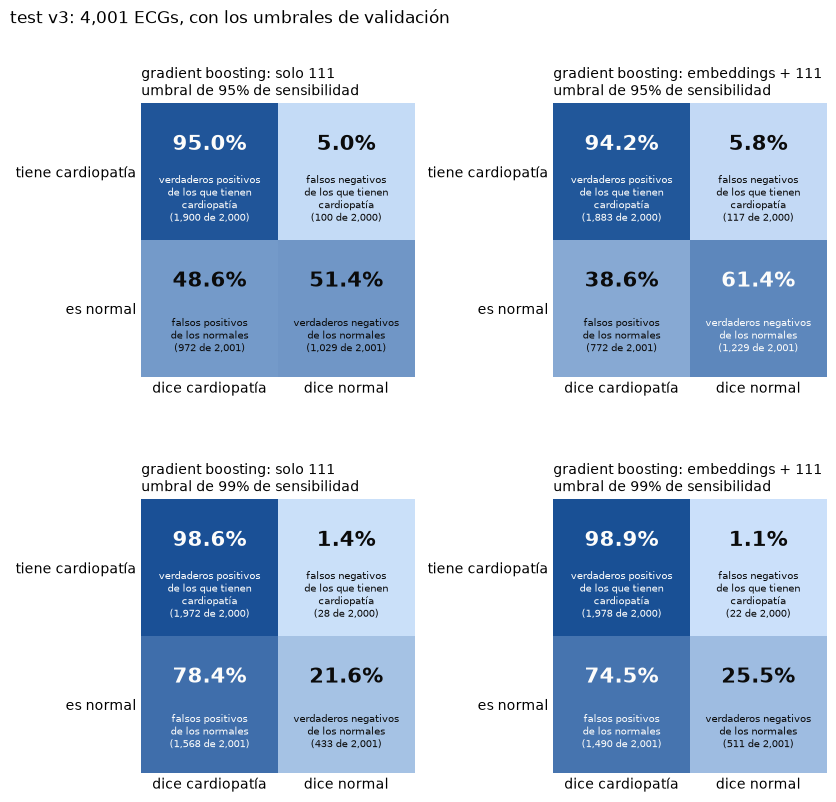

cardiopatías que se escapan (%)  \
conjunto umbral modelo                                                                 
test v3  95%    regresión: embeddings + 111                                      6.2   
                regresión: solo 111                                              6.0   
                gradient boosting: solo 111                                      5.0   
                gradient boosting: embeddings + 111                              5.8   
         99%    regresión: embeddings + 111                                      0.8   
                regresión: solo 111                                              1.3   
                gradient boosting: solo 111                                      1.4   
                gradient boosting: embeddings + 111                              1.1   

                                                     normales a revisión (%)  \
conjunto umbral modelo                                                         
test v3  95%    regresión: embeddings + 111                             39.3   
                regresión: solo 111                                     61.3   
                gradient boosting: solo 111                             48.6   
                gradient boosting: embeddings + 111                     38.6   
         99%    regresión: embeddings + 111                             82.7   
                regresión: solo 111                                     88.6   
                gradient boosting: solo 111                             78.4   
                gradient boosting: embeddings + 111                     74.5   

                                                        F1     F2  
conjunto umbral modelo                                             
test v3  95%    regresión: embeddings + 111          0.805  0.879  
                regresión: solo 111                  0.737  0.847  
                gradient boosting: solo 111          0.780  0.874  
                gradient boosting: embeddings + 111  0.809  0.884  
         99%    regresión: embeddings + 111          0.704  0.852  
                regresión: solo 111                  0.687  0.840  
                gradient boosting: solo 111          0.712  0.854  
                gradient boosting: embeddings + 111  0.723  0.862

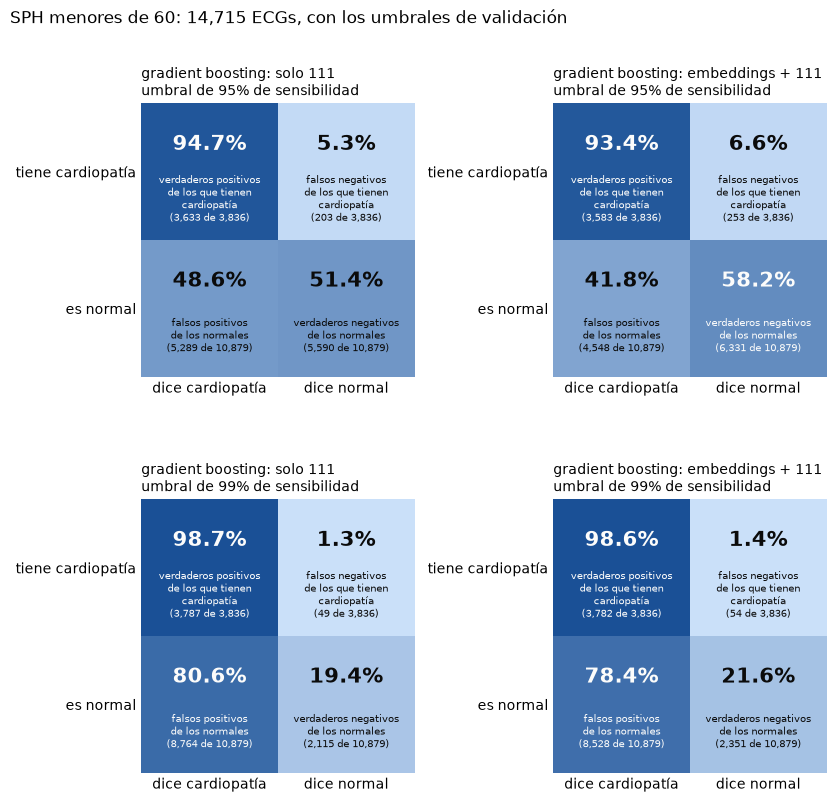

cardiopatías que se escapan (%)  \
conjunto          umbral modelo                                                                 
SPH menores de 60 95%    regresión: embeddings + 111                                      6.5   
                         regresión: solo 111                                              5.5   
                         gradient boosting: solo 111                                      5.3   
                         gradient boosting: embeddings + 111                              6.6   
                  99%    regresión: embeddings + 111                                      0.7   
                         regresión: solo 111                                              0.8   
                         gradient boosting: solo 111                                      1.3   
                         gradient boosting: embeddings + 111                              1.4   

                                                              normales a revisión (%)  \
conjunto          umbral modelo                                                         
SPH menores de 60 95%    regresión: embeddings + 111                             43.1   
                         regresión: solo 111                                     67.8   
                         gradient boosting: solo 111                             48.6   
                         gradient boosting: embeddings + 111                     41.8   
                  99%    regresión: embeddings + 111                             88.3   
                         regresión: solo 111                                     93.4   
                         gradient boosting: solo 111                             80.6   
                         gradient boosting: embeddings + 111                     78.4   

                                                                 F1     F2  
conjunto          umbral modelo                                             
SPH menores de 60 95%    regresión: embeddings + 111          0.593  0.760  
                         regresión: solo 111                  0.489  0.688  
                         gradient boosting: solo 111          0.570  0.749  
                         gradient boosting: embeddings + 111  0.599  0.763  
                  99%    regresión: embeddings + 111          0.442  0.663  
                         regresión: solo 111                  0.428  0.649  
                         gradient boosting: solo 111          0.462  0.679  
                         gradient boosting: embeddings + 111  0.468  0.684

AUROC por cardiopatía en test v3: 34 cardiopatías modeladas con al menos 20 casos


,regresión: solo 111,regresión: embeddings + 111,gradient boosting: solo 111,gradient boosting: embeddings + 111
onda T anormal,0.822,0.904,0.898,0.915
cambios del segmento ST,0.722,0.830,0.821,0.846
anomalía inespecífica ST-T,0.760,0.836,0.820,0.839
bloqueo de rama derecha,0.954,0.974,0.973,0.974
hipertrofia ventricular izquierda,0.906,0.938,0.952,0.952
QRS anormal,0.839,0.900,0.822,0.867
extrasístole ventricular,0.951,0.966,0.955,0.967
depresión del ST,0.849,0.877,0.874,0.902
onda T invertida,0.760,0.859,0.818,0.858
bloqueo incompleto de rama derecha,0.886,0.921,0.900,0.916


AUROC por cardiopatía en SPH menores de 60: 16 cardiopatías modeladas con al menos 20 casos


,regresión: solo 111,regresión: embeddings + 111,gradient boosting: solo 111,gradient boosting: embeddings + 111
onda T anormal,0.831,0.927,0.920,0.937
cambios del segmento ST,0.736,0.855,0.820,0.856
bloqueo de rama derecha,0.977,0.997,0.994,0.995
hipertrofia ventricular izquierda,0.964,0.982,0.991,0.988
extrasístole ventricular,0.964,0.971,0.971,0.990
depresión del ST,0.858,0.873,0.907,0.889
onda T invertida,0.856,0.912,0.908,0.927
bloqueo incompleto de rama derecha,0.734,0.838,0.772,0.817
flutter auricular,0.914,0.998,0.950,0.999
bloqueo AV de primer grado,0.892,0.997,0.975,0.996


In [27]:
puntajes_gb_test = {f"gradient boosting: {n}": puntuar(modelos_gb[n], entradas_test[n]) for n in entradas_gb}
puntajes_gb_sph = {f"gradient boosting: {n}": puntuar(modelos_gb[n], entradas_sph[n]) for n in entradas_gb}
comparados_test = {f"regresión: {n}": puntajes_test[f"regresión: {n}"] for n in entradas_gb} | puntajes_gb_test
comparados_sph = {f"regresión: {n}": puntajes_sph[f"regresión: {n}"] for n in entradas_gb} | puntajes_gb_sph
resultados_gb = pd.DataFrame([{"modelo": m, "conjunto": "validación v3", **medidas(y_val, p["cualquier cardiopatía"].to_numpy())} for m, p in comparados.items()]
                             + [{"modelo": m, "conjunto": "test v3", **medidas(y_test, p["cualquier cardiopatía"].to_numpy())} for m, p in comparados_test.items()]
                             + [{"modelo": m, "conjunto": nombre, **medidas(y_sph[mascara], p["cualquier cardiopatía"].to_numpy()[mascara])}
                                for m, p in comparados_sph.items() for nombre, mascara in conjuntos.items()])
resultados_gb.to_csv(CARPETA / "resultados_gb_val_prueba.csv", index=False)
display(resultados_gb.pivot_table(index="modelo", columns="conjunto", values="AUROC", sort=False)[COLUMNAS_PRUEBA]
        .rename_axis(columns="AUROC").round(3))

matrices_gb_prueba, modelos_regresion = [], [f"regresión: {n}" for n in entradas_gb]
for nombre, y, puntajes_conjunto, filtro in [("test v3", y_test, puntajes_gb_test, slice(None)), ("SPH menores de 60", y_sph[menor], puntajes_gb_sph, menor)]:
    tabla = mostrar_matrices(y, {m: p["cualquier cardiopatía"].to_numpy()[filtro] for m, p in puntajes_conjunto.items()},
                             f"{nombre}: {len(y):,} ECGs, con los umbrales de validación").assign(conjunto=nombre)
    matrices_gb_prueba.append(tabla)
    regresion = pd.concat(matrices_prueba).query("conjunto == @nombre and modelo in @modelos_regresion")
    display(pd.concat([regresion, tabla]).sort_values("umbral", kind="stable").set_index(["conjunto", "umbral", "modelo"])[list(REDONDEO)].round(REDONDEO))
pd.concat(matrices_gb_prueba).to_csv(CARPETA / "matrices_confusion_gb_prueba.csv", index=False)

for nombre, objetivo, puntajes_conjunto, columnas in [("test v3", objetivo_test, comparados_test, medibles_test),
                                                      ("SPH menores de 60", objetivo_sph[menor], {m: p[menor] for m, p in comparados_sph.items()}, medibles_sph)]:
    print(f"AUROC por cardiopatía en {nombre}: {len(columnas)} cardiopatías modeladas con al menos {MIN_CASOS_VAL} casos")
    tabla = pd.DataFrame({m: aurocs(objetivo, p, columnas) for m, p in puntajes_conjunto.items()})
    display(pd.concat([tabla, tabla.mean().rename("macro").to_frame().T]).round(3))

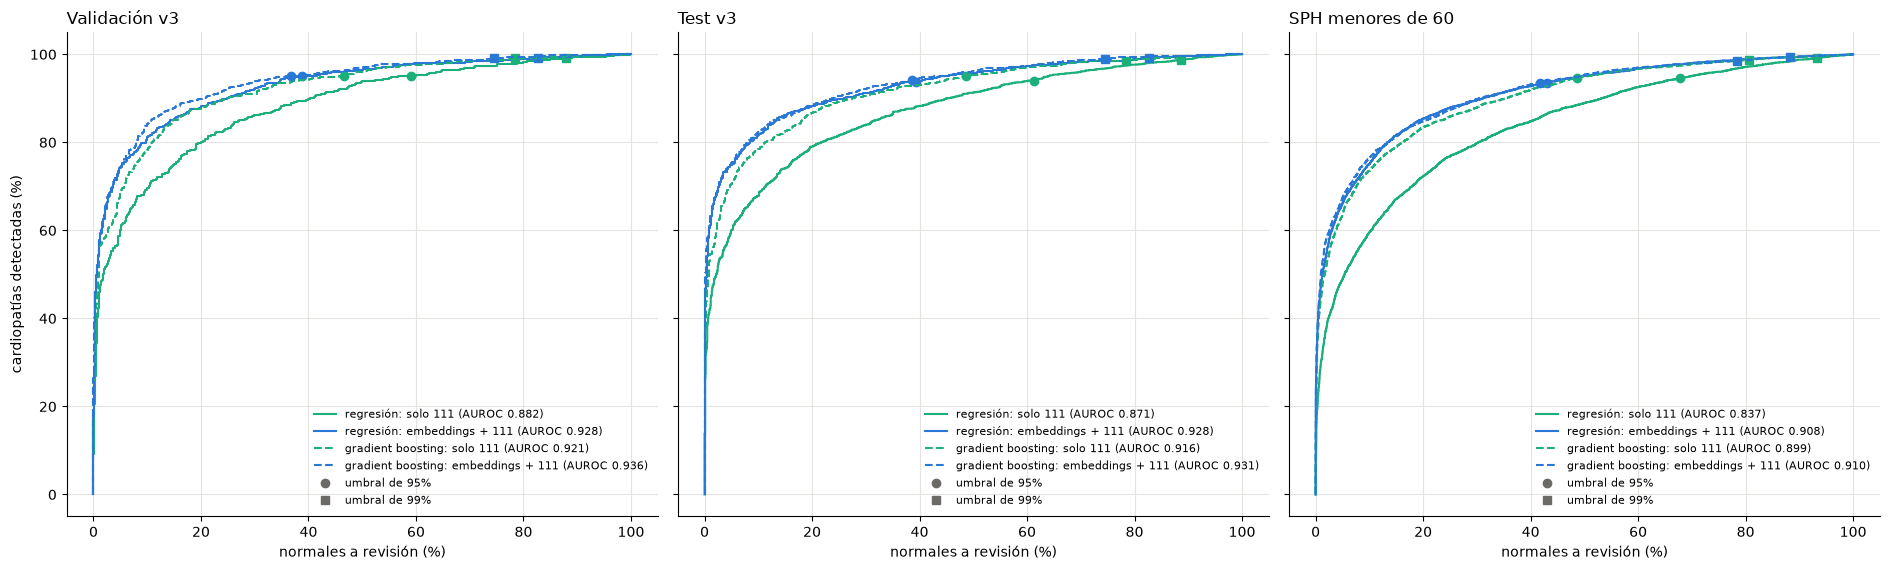

In [28]:
# Curvas ROC de cualquier cardiopatía: cada punto de la curva es un umbral distinto.
# Círculo y cuadrado: los umbrales de 95% y 99% elegidos en validación, aplicados sin cambio en la prueba.
from matplotlib.lines import Line2D

ESTILO = {"regresión: solo 111": ("#1baf7a", "-"), "regresión: embeddings + 111": ("#2a78d6", "-"),
          "gradient boosting: solo 111": ("#1baf7a", "--"), "gradient boosting: embeddings + 111": ("#2a78d6", "--")}
conjuntos_roc = {"Validación v3": (y_val, {m: p["cualquier cardiopatía"].to_numpy() for m, p in comparados.items()}),
                 "Test v3": (y_test, {m: p["cualquier cardiopatía"].to_numpy() for m, p in comparados_test.items()}),
                 "SPH menores de 60": (y_sph[menor], {m: p["cualquier cardiopatía"].to_numpy()[menor] for m, p in comparados_sph.items()})}
fig, ejes = plt.subplots(1, 3, figsize=(19, 5.8), sharey=True)
for ax, (titulo, (y, binarios)) in zip(ejes, conjuntos_roc.items()):
    for modelo, p in binarios.items():
        color, linea = ESTILO[modelo]
        fpr, tpr, _ = roc_curve(y, p)
        ax.plot(100 * fpr, 100 * tpr, color=color, linestyle=linea, linewidth=1.5, label=f"{modelo} (AUROC {roc_auc_score(y, p):.3f})")
        for s, marcador in zip(SENSIBILIDADES, ["o", "s"]):
            alerta = p >= umbrales[(modelo, s)]
            ax.plot(100 * alerta[y == 0].mean(), 100 * alerta[y == 1].mean(), marker=marcador, color=color, markersize=6, linestyle="none")
    ax.set_title(titulo, loc="left")
    ax.set_xlabel("normales a revisión (%)")
    ax.grid(color="#e4e3df", linewidth=0.8)
    ax.set_axisbelow(True)
    for borde in ["top", "right"]:
        ax.spines[borde].set_visible(False)
    marcas = [Line2D([], [], marker=m, color="#6b6a66", linestyle="none", label=f"umbral de {s:.0%}") for s, m in zip(SENSIBILIDADES, ["o", "s"])]
    ax.legend(handles=ax.get_legend_handles_labels()[0] + marcas, frameon=False, fontsize=8, loc="lower right")
ejes[0].set_ylabel("cardiopatías detectadas (%)")
plt.tight_layout()
plt.show()

### 10.3 Cardiopatías que mejor se detectan

Gradient boosting con embeddings + 111

In [29]:
MODELO_LISTA = "gradient boosting: embeddings + 111"
AUROC_MINIMO = 0.95          # una cardiopatía entra a la lista si el AUROC de su modelo en validación llega a esto

p_val_lista, p_test_lista, p_sph_lista = puntajes_gb[MODELO_LISTA], puntajes_gb_test[MODELO_LISTA], puntajes_gb_sph[MODELO_LISTA]
tabla_lista = pd.DataFrame({
    "casos en validación": objetivo_val[medibles].sum(),
    "AUROC en validación": aurocs(objetivo_val, p_val_lista, medibles),
    "casos en test v3": objetivo_test[medibles_test].sum(),
    "AUROC en test v3": aurocs(objetivo_test, p_test_lista, medibles_test),
    "casos en SPH menores de 60": objetivo_sph.loc[menor, medibles_sph].sum(),
    "AUROC en SPH menores de 60": aurocs(objetivo_sph[menor], p_sph_lista[menor], medibles_sph),
}).dropna(subset=["AUROC en validación"]).sort_values("AUROC en validación", ascending=False)
casos = [c for c in tabla_lista if c.startswith("casos")]
tabla_lista[casos] = tabla_lista[casos].astype("Int64")
mejor_detectadas = tabla_lista.index[tabla_lista["AUROC en validación"] >= AUROC_MINIMO].tolist()
print(f"Cardiopatías con AUROC de al menos {AUROC_MINIMO} en validación: {len(mejor_detectadas)} de {len(medibles)}")
with pd.option_context("display.max_colwidth", None):
    display(tabla_lista.assign(**{"en la lista": tabla_lista.index.isin(mejor_detectadas)}).rename_axis("cardiopatía").round(3))

Cardiopatías con AUROC de al menos 0.95 en validación: 9 de 29


,casos en validación,AUROC en validación,casos en test v3,AUROC en test v3,casos en SPH menores de 60,AUROC en SPH menores de 60,en la lista
cardiopatía,,,,,,,
taquicardia supraventricular,28,0.999,54,0.998,<NA>,NaN,True
flutter auricular,56,0.990,127,0.990,20,0.999,True
bloqueo fascicular anterior izquierdo,26,0.985,50,0.991,63,0.995,True
desviación del eje a la derecha,38,0.983,53,0.983,<NA>,NaN,True
bloqueo AV de primer grado,38,0.976,85,0.985,63,0.996,True
QT prolongado,38,0.972,82,0.950,<NA>,NaN,True
bloqueo de rama derecha,85,0.972,149,0.974,241,0.995,True
desviación del eje a la izquierda,30,0.964,49,0.972,<NA>,NaN,True
infarto anteroseptal,26,0.963,65,0.966,22,0.995,True


In [30]:
# Cada conjunto de prueba en tres grupos, con la probabilidad de cualquier cardiopatía y los umbrales de validación
print("Umbrales: " + ", ".join(f"{s:.0%} de sensibilidad = {umbrales[(MODELO_LISTA, s)]:.1%} de probabilidad" for s in SENSIBILIDADES))
for nombre, objetivo, p, columnas in [("test v3", objetivo_test, p_test_lista["cualquier cardiopatía"].to_numpy(), medibles_test),
                                      ("SPH menores de 60", objetivo_sph[menor], p_sph_lista["cualquier cardiopatía"].to_numpy()[menor], medibles_sph)]:
    y = objetivo["cualquier cardiopatía"].to_numpy()
    con_lista = objetivo[[c for c in mejor_detectadas if c in objetivo]].any(axis=1).to_numpy()
    grupos = {"normales": y == 0, "con alguna cardiopatía de la lista": con_lista, "con cardiopatía, ninguna de la lista": (y == 1) & ~con_lista}
    filas_grupos = []
    for grupo, en_grupo in grupos.items():
        fila = {"grupo": grupo, "ECGs": en_grupo.sum()}
        if grupo != "normales":
            fila["AUROC contra normales"] = roc_auc_score(np.r_[np.ones(en_grupo.sum()), np.zeros((y == 0).sum())], np.r_[p[en_grupo], p[y == 0]])
        for s in SENSIBILIDADES:
            fila[f"a revisión con el umbral de {s:.0%} (%)"] = 100 * (p[en_grupo] >= umbrales[(MODELO_LISTA, s)]).mean()
        filas_grupos.append(fila)
    print(nombre)
    display(pd.DataFrame(filas_grupos).set_index("grupo").round(3).round({f"a revisión con el umbral de {s:.0%} (%)": 1 for s in SENSIBILIDADES}))

    # Cada cardiopatía de la lista con al menos MIN_CASOS_VAL casos en el conjunto: cuántos de sus ECGs van a revisión
    en_conjunto = [c for c in mejor_detectadas if c in columnas]
    display(pd.DataFrame({"casos": [objetivo[c].sum() for c in en_conjunto],
                          **{f"a revisión con el umbral de {s:.0%} (%)": [100 * (p[objetivo[c].to_numpy() == 1] >= umbrales[(MODELO_LISTA, s)]).mean()
                                                                          for c in en_conjunto] for s in SENSIBILIDADES}},
                         index=pd.Index(en_conjunto, name=f"cardiopatía de la lista ({nombre})")).round(1))

Umbrales: 95% de sensibilidad = 0.1% de probabilidad, 99% de sensibilidad = 0.0% de probabilidad
test v3


,ECGs,a revisión con el umbral de 95% (%),a revisión con el umbral de 99% (%),AUROC contra normales
grupo,,,,
normales,2001,38.6,74.5,NaN
con alguna cardiopatía de la lista,647,97.1,99.5,0.962
"con cardiopatía, ninguna de la lista",1353,92.8,98.6,0.917


,casos,a revisión con el umbral de 95% (%),a revisión con el umbral de 99% (%)
cardiopatía de la lista (test v3),,,
taquicardia supraventricular,54,100.0,100.0
flutter auricular,127,100.0,100.0
bloqueo fascicular anterior izquierdo,50,98.0,100.0
desviación del eje a la derecha,53,96.2,100.0
bloqueo AV de primer grado,85,96.5,98.8
QT prolongado,82,95.1,98.8
bloqueo de rama derecha,149,96.0,99.3
desviación del eje a la izquierda,49,100.0,100.0
infarto anteroseptal,65,95.4,100.0


SPH menores de 60


,ECGs,a revisión con el umbral de 95% (%),a revisión con el umbral de 99% (%),AUROC contra normales
grupo,,,,
normales,10879,41.8,78.4,NaN
con alguna cardiopatía de la lista,421,99.5,100.0,0.980
"con cardiopatía, ninguna de la lista",3415,92.6,98.4,0.901


,casos,a revisión con el umbral de 95% (%),a revisión con el umbral de 99% (%)
cardiopatía de la lista (SPH menores de 60),,,
flutter auricular,20,100.0,100.0
bloqueo fascicular anterior izquierdo,63,100.0,100.0
bloqueo AV de primer grado,63,98.4,100.0
bloqueo de rama derecha,241,99.6,100.0
infarto anteroseptal,22,100.0,100.0
